# Clasificación Cuántica de Crédito Financiero
## Comparación de Enfoques Cuánticos e Híbridos para Aprobación de Crédito

**Dataset:** Statlog (Australian Credit Approval) - UCI Machine Learning Repository

**Objetivo:** Comparar tres enfoques de clasificación cuántica/híbrida:
1. **QSVM** - Quantum Support Vector Machine con kernel cuántico
2. **QNN** - Red Neuronal Cuántica
3. **Híbrido** - Red neuronal clásica-cuántica

---

### Tabla de Contenidos
1. [Configuración e Instalación](#0-configuración)
2. [Carga y Análisis de Datos](#1-datos)
3. [Preprocesamiento](#preprocesamiento)
4. [QSVM - Quantum Support Vector Machine](#2a-qsvm)
5. [Red Neuronal Cuántica (QNN)](#2b-qnn)
6. [Red Híbrida Clásica-Cuántica](#2c-híbrido)
7. [Baseline Clásico](#2d-baseline)
8. [Análisis Comparativo y Conclusiones](#3-análisis)


<a name="0-configuración"></a>
## 0. Configuración e Instalación

Instalamos las dependencias necesarias y configuramos el entorno para reproducibilidad.


In [4]:
# Instalación de dependencias
# %pip install pennylane torch torchinfo scikit-learn pandas matplotlib seaborn -q


In [5]:
# =============================================================================
# IMPORTS
# =============================================================================

# Standard library
import time
import warnings
warnings.filterwarnings('ignore')

# Third-party: Data manipulation
import numpy as np
import pandas as pd

# Third-party: Visualization
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns

# Third-party: Machine Learning
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                             f1_score, confusion_matrix, roc_curve, auc,
                             classification_report)

# Third-party: Deep Learning
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchinfo import summary

# Third-party: Quantum Computing
import pennylane as qml

# Local: Utilidades de entrenamiento del curso
from minitorch import NumpyDataset, train, set_seed

# =============================================================================
# CONFIGURACIÓN GLOBAL
# =============================================================================

# Semilla para reproducibilidad
rs = 42
set_seed(rs)

# Configuración de matplotlib para gráficas estilo paper académico
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'DejaVu Serif', 'Computer Modern Roman'],
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'legend.fontsize': 10,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.figsize': (8, 5),
    'figure.dpi': 150,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'legend.framealpha': 0.9,
    'legend.edgecolor': 'gray',
})

# Paleta de colores consistente para los modelos
COLORS = {
    'qsvm': '#2E86AB',      # Azul
    'qnn_1': '#A23B72',     # Magenta
    'qnn_2': '#F18F01',     # Naranja
    'hybrid_1': '#C73E1D',  # Rojo
    'hybrid_2': '#3B1F2B',  # Púrpura oscuro
    'classical': '#44AF69', # Verde
}

print(f"PennyLane version: {qml.__version__}")
print(f"PyTorch version: {torch.__version__}")
print(f"Semilla aleatoria: {rs}")


PennyLane version: 0.43.2
PyTorch version: 2.5.1+cpu
Semilla aleatoria: 42


<a name="1-datos"></a>
## 1. Carga y Análisis del Conjunto de Datos

### 1.1 Descripción del Dataset

El dataset **Statlog (Australian Credit Approval)** contiene información sobre solicitudes de tarjetas de crédito en Australia. Por razones de confidencialidad, los nombres de los atributos y valores han sido anonimizados. Se ha seleccionado este dataset, ya que contiene tanto datos categóricos, como continuos, como discretos. Además del interés propio en el sector financiero. 

- **Fuente:** UCI Machine Learning Repository
- **Instancias:** 690
- **Atributos:** 14 (6 numéricos, 8 categóricos)
- **Clases:** Binaria (aprobado/rechazado)
- **Valores faltantes:** Sí (indicados con '?')


In [6]:
# =============================================================================
# CARGA DEL DATASET
# =============================================================================

# URL del dataset Australian Credit Approval (UCI)
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/australian/australian.dat"

# Definimos nombres de columnas (A1-A14 para atributos, class para la etiqueta)
column_names = [f'A{i}' for i in range(1, 15)] + ['class']

# Cargamos los datos (separador espacio, sin cabecera)
df = pd.read_csv(url, sep=' ', header=None, names=column_names)

print(f"Dataset cargado exitosamente: {df.shape[0]} instancias, {df.shape[1]} columnas")
df.head(10)


Dataset cargado exitosamente: 690 instancias, 15 columnas


,A1,A2,A3,A4,A5,A6,A7,A8,A9,A10,A11,A12,A13,A14,class
0,1,22.08,11.460,2,4,4,1.585,0,0,0,1,2,100,1213,0
1,0,22.67,7.000,2,8,4,0.165,0,0,0,0,2,160,1,0
2,0,29.58,1.750,1,4,4,1.250,0,0,0,1,2,280,1,0
3,0,21.67,11.500,1,5,3,0.000,1,1,11,1,2,0,1,1
4,1,20.17,8.170,2,6,4,1.960,1,1,14,0,2,60,159,1
5,0,15.83,0.585,2,8,8,1.500,1,1,2,0,2,100,1,1
6,1,17.42,6.500,2,3,4,0.125,0,0,0,0,2,60,101,0
7,0,58.67,4.460,2,11,8,3.040,1,1,6,0,2,43,561,1
8,1,27.83,1.000,1,2,8,3.000,0,0,0,0,2,176,538,0
9,0,55.75,7.080,2,4,8,6.750,1,1,3,1,2,100,51,0


### 1.2 Análisis Exploratorio de Datos (EDA)


In [7]:
# Información general del dataset
print("="*60)
print("INFORMACIÓN DEL DATASET")
print("="*60)
df.info()
print("\n")

# Estadísticas descriptivas
print("="*60)
print("ESTADÍSTICAS DESCRIPTIVAS")
print("="*60)
df.describe()


INFORMACIÓN DEL DATASET
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 690 entries, 0 to 689
Data columns (total 15 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   A1      690 non-null    int64  
 1   A2      690 non-null    float64
 2   A3      690 non-null    float64
 3   A4      690 non-null    int64  
 4   A5      690 non-null    int64  
 5   A6      690 non-null    int64  
 6   A7      690 non-null    float64
 7   A8      690 non-null    int64  
 8   A9      690 non-null    int64  
 9   A10     690 non-null    int64  
 10  A11     690 non-null    int64  
 11  A12     690 non-null    int64  
 12  A13     690 non-null    int64  
 13  A14     690 non-null    int64  
 14  class   690 non-null    int64  
dtypes: float64(3), int64(12)
memory usage: 81.0 KB


ESTADÍSTICAS DESCRIPTIVAS


,A1,A2,A3,A4,A5,A6,A7,A8,A9,A10,A11,A12,A13,A14,class
count,690.000000,690.000000,690.000000,690.000000,690.000000,690.000000,690.000000,690.000000,690.000000,690.00000,690.000000,690.000000,690.000000,690.000000,690.000000
mean,0.678261,31.568203,4.758725,1.766667,7.372464,4.692754,2.223406,0.523188,0.427536,2.40000,0.457971,1.928986,184.014493,1018.385507,0.444928
std,0.467482,11.853273,4.978163,0.430063,3.683265,1.992316,3.346513,0.499824,0.495080,4.86294,0.498592,0.298813,172.159274,5210.102598,0.497318
min,0.000000,13.750000,0.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.00000,0.000000,1.000000,0.000000,1.000000,0.000000
25%,0.000000,22.670000,1.000000,2.000000,4.000000,4.000000,0.165000,0.000000,0.000000,0.00000,0.000000,2.000000,80.000000,1.000000,0.000000
50%,1.000000,28.625000,2.750000,2.000000,8.000000,4.000000,1.000000,1.000000,0.000000,0.00000,0.000000,2.000000,160.000000,6.000000,0.000000
75%,1.000000,37.707500,7.207500,2.000000,10.000000,5.000000,2.625000,1.000000,1.000000,3.00000,1.000000,2.000000,272.000000,396.500000,1.000000
max,1.000000,80.250000,28.000000,3.000000,14.000000,9.000000,28.500000,1.000000,1.000000,67.00000,1.000000,3.000000,2000.000000,100001.000000,1.000000


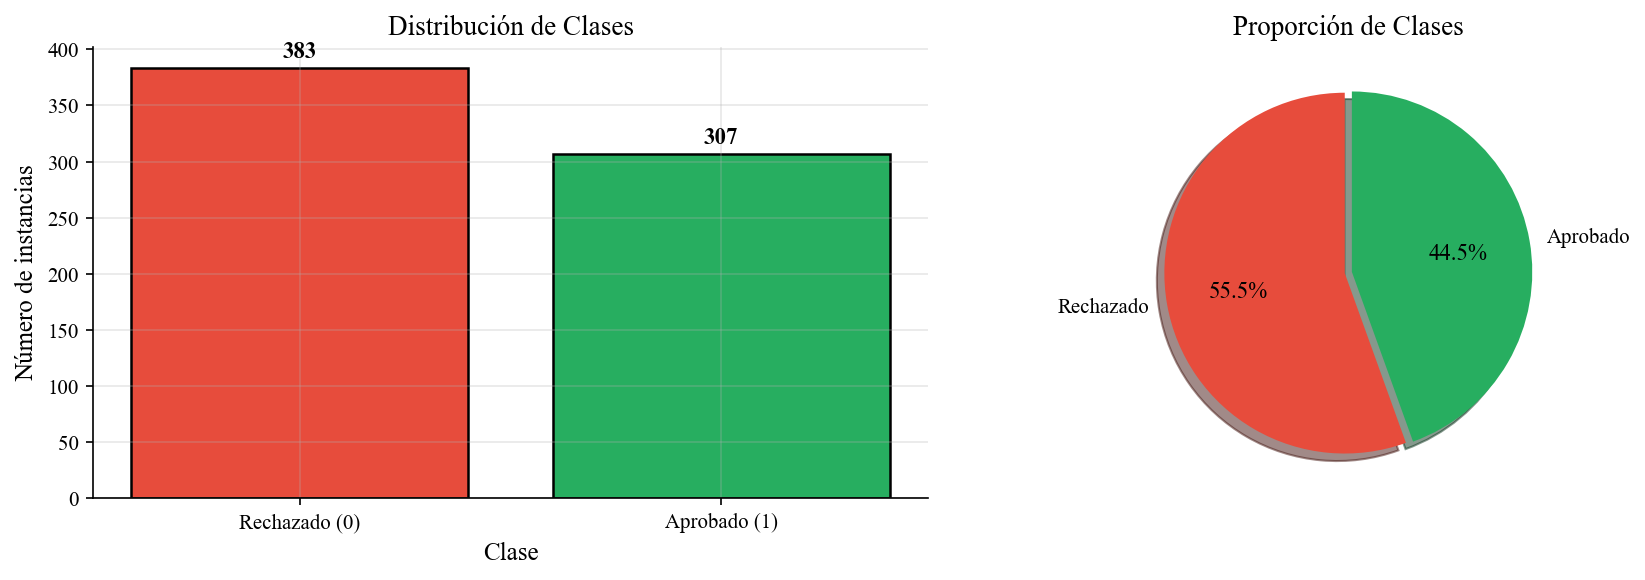


Balance de clases:
  - Clase 0 (Rechazado): 383 (55.5%)
  - Clase 1 (Aprobado): 307 (44.5%)
  - Ratio: 1:0.80


In [8]:
# =============================================================================
# ANÁLISIS DEL BALANCE DE CLASES
# =============================================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Gráfico de barras
class_counts = df['class'].value_counts().sort_index()
colors = ['#E74C3C', '#27AE60']  # Rojo para rechazado, Verde para aprobado
bars = axes[0].bar(['Rechazado (0)', 'Aprobado (1)'], class_counts.values, color=colors, edgecolor='black', linewidth=1.2)
axes[0].set_xlabel('Clase')
axes[0].set_ylabel('Número de instancias')
axes[0].set_title('Distribución de Clases')

# Añadir valores sobre las barras
for bar, count in zip(bars, class_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5, 
                 str(count), ha='center', va='bottom', fontsize=11, fontweight='bold')

# Gráfico de pastel
axes[1].pie(class_counts.values, labels=['Rechazado', 'Aprobado'], autopct='%1.1f%%',
            colors=colors, explode=(0.02, 0.02), shadow=True, startangle=90)
axes[1].set_title('Proporción de Clases')

plt.tight_layout()
plt.savefig('class_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

# Mostrar estadísticas
print(f"\nBalance de clases:")
print(f"  - Clase 0 (Rechazado): {class_counts[0]} ({100*class_counts[0]/len(df):.1f}%)")
print(f"  - Clase 1 (Aprobado): {class_counts[1]} ({100*class_counts[1]/len(df):.1f}%)")
print(f"  - Ratio: 1:{class_counts[1]/class_counts[0]:.2f}")


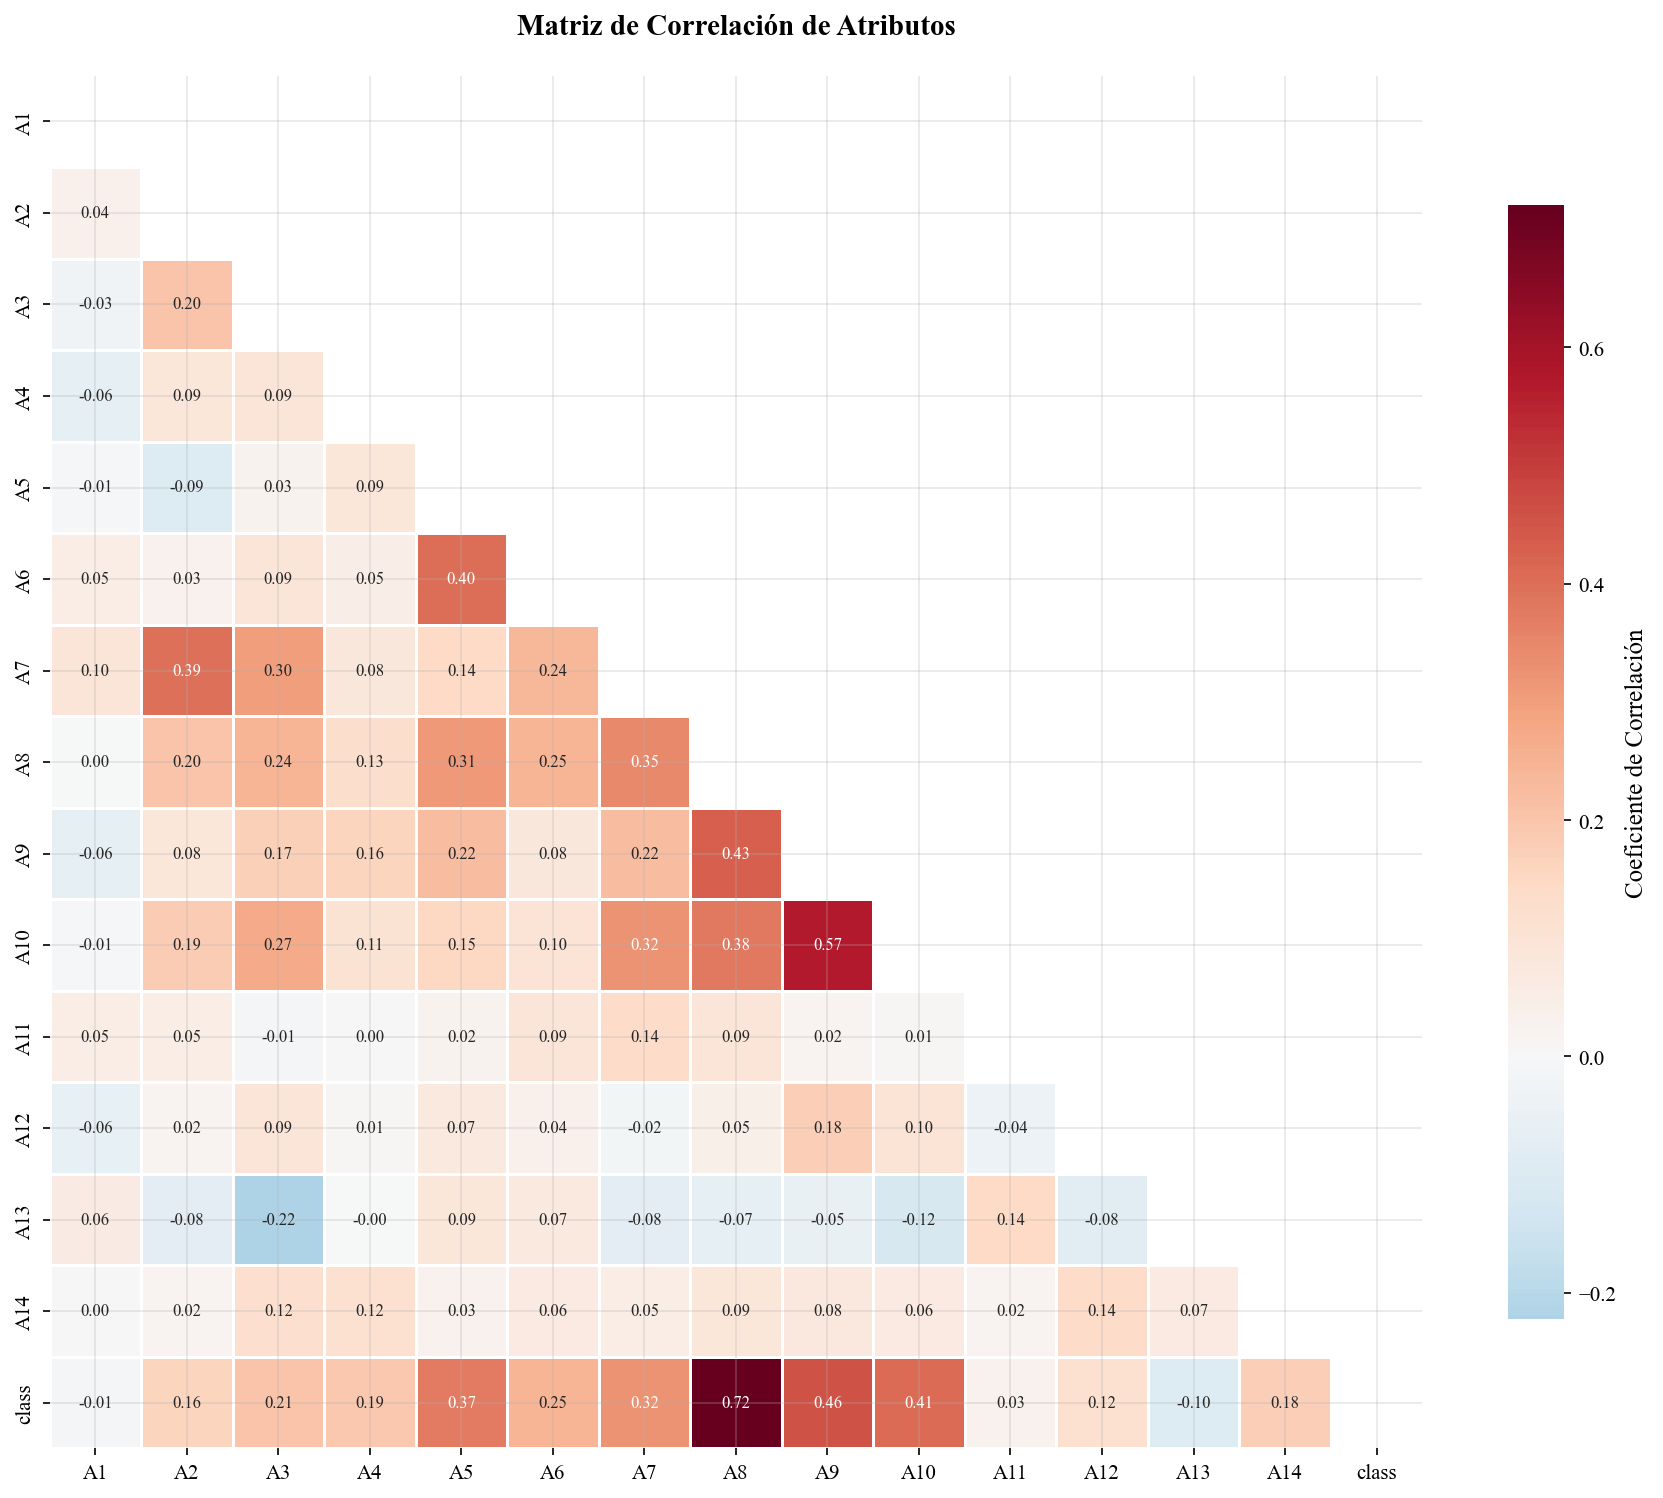


Correlaciones más significativas con la clase objetivo:
  A8: +0.720
  A9: +0.458
  A10: +0.406
  A5: +0.374
  A7: +0.322


In [9]:
# =============================================================================
# MATRIZ DE CORRELACIÓN
# =============================================================================

plt.figure(figsize=(12, 10))

# Calculamos la matriz de correlación
corr_matrix = df.corr()

# Creamos el heatmap con estilo académico
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))  # Máscara para triángulo superior
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, square=True, linewidths=0.5,
            cbar_kws={"shrink": 0.8, "label": "Coeficiente de Correlación"},
            annot_kws={"size": 8})

plt.title('Matriz de Correlación de Atributos', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('correlation_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

# Correlaciones más fuertes con la clase objetivo
print("\nCorrelaciones más significativas con la clase objetivo:")
class_corr = corr_matrix['class'].drop('class').abs().sort_values(ascending=False)
for attr, corr in class_corr.head(5).items():
    print(f"  {attr}: {corr_matrix.loc[attr, 'class']:+.3f}")


<a name="preprocesamiento"></a>
### 1.3 Preprocesamiento

El preprocesamiento es **crítico** para los circuitos cuánticos. Aplicamos un pipeline metodológicamente correcto:

1. **Tratamiento diferenciado por tipo de variable:**
   - **Variables categóricas** (A1, A4, A5, A6, A8, A9, A11, A12): Se aplica **One-Hot Encoding** para evitar imponer orden artificial.
   - **Variables numéricas** (A2, A3, A7, A10, A13, A14): Se aplica **MinMaxScaler** a $[0, \pi]$.
   - Usamos `ColumnTransformer` de sklearn para aplicar transformaciones diferentes a cada grupo.

2. **PCA (Principal Component Analysis)**: Reducimos a 4 componentes principales.
   - **Justificación:** Simular 14+ qubits es computacionalmente prohibitivo ($2^{14} = 16,384$ amplitudes). 
   - Con 4 qubits, el espacio de Hilbert es manejable ($2^4 = 16$ amplitudes).
   - PCA preserva la máxima varianza posible en las nuevas dimensiones.

3. **Escalado final a $[0, \pi]$**: Necesario para *Angle Embedding*, donde cada feature se codifica como un ángulo de rotación en un qubit.

4. **División estratificada**: Mantenemos la proporción de clases en train/validation/test.


In [10]:
# =============================================================================
# SEPARACIÓN DE FEATURES Y TARGET
# =============================================================================

# Separamos features (X) y target (y)
X = df.drop('class', axis=1).values
y = df['class'].values

print(f"Shape de X: {X.shape}")
print(f"Shape de y: {y.shape}")
print(f"Tipo de datos X: {X.dtype}")
print(f"Tipo de datos y: {y.dtype}")


Shape de X: (690, 14)
Shape de y: (690,)
Tipo de datos X: float64
Tipo de datos y: int64


In [11]:
# =============================================================================
# DIVISIÓN TRAIN / VALIDATION / TEST
# =============================================================================

# Primera división: separamos test (20%)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=rs
)

# Segunda división: separamos validation (20% del restante = 16% del total)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.20, stratify=y_temp, random_state=rs
)

print("División de datos (estratificada):")
print(f"  - Train:      {len(X_train)} muestras ({100*len(X_train)/len(X):.1f}%)")
print(f"  - Validation: {len(X_val)} muestras ({100*len(X_val)/len(X):.1f}%)")
print(f"  - Test:       {len(X_test)} muestras ({100*len(X_test)/len(X):.1f}%)")
print(f"\nBalance en train: {np.mean(y_train):.2%} clase 1")
print(f"Balance en test:  {np.mean(y_test):.2%} clase 1")


División de datos (estratificada):
  - Train:      441 muestras (63.9%)
  - Validation: 111 muestras (16.1%)
  - Test:       138 muestras (20.0%)

Balance en train: 44.67% clase 1
Balance en test:  44.20% clase 1


In [12]:
# =============================================================================
# PREPROCESAMIENTO CON COLUMNTRANSFORMER
# =============================================================================

# Definimos las columnas según su tipo (basado en documentación UCI)
# Índices de columnas categóricas: A1(0), A4(3), A5(4), A6(5), A8(7), A9(8), A11(10), A12(11)
categorical_cols = [0, 3, 4, 5, 7, 8, 10, 11]
# Índices de columnas numéricas: A2(1), A3(2), A7(6), A10(9), A13(12), A14(13)
numerical_cols = [1, 2, 6, 9, 12, 13]

print("Preprocesamiento metodológicamente correcto:")
print(f"  - Columnas categóricas: {categorical_cols} (One-Hot Encoding)")
print(f"  - Columnas numéricas: {numerical_cols} (MinMaxScaler [0, π])")

# Creamos el ColumnTransformer
# - OneHotEncoder para categóricas (sparse_output=False para compatibilidad con PCA)
# - MinMaxScaler para numéricas, escalando a [0, π]
preprocessor = ColumnTransformer(
    transformers=[
        ('num', MinMaxScaler(feature_range=(0, np.pi)), numerical_cols),
        ('cat', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), categorical_cols)
    ],
    remainder='drop'
)

# Ajustamos SOLO con datos de train para evitar data leakage
X_train_preprocessed = preprocessor.fit_transform(X_train)
X_val_preprocessed = preprocessor.transform(X_val)
X_test_preprocessed = preprocessor.transform(X_test)

print(f"\nDimensiones después del preprocesamiento:")
print(f"  - X_train: {X_train_preprocessed.shape} (de {X_train.shape[1]} a {X_train_preprocessed.shape[1]} features)")
print(f"  - Numéricas escaladas: {len(numerical_cols)}")
print(f"  - Features one-hot: {X_train_preprocessed.shape[1] - len(numerical_cols)}")
print(f"\nRango de columnas numéricas: [{X_train_preprocessed[:, :len(numerical_cols)].min():.4f}, {X_train_preprocessed[:, :len(numerical_cols)].max():.4f}]")


Preprocesamiento metodológicamente correcto:
  - Columnas categóricas: [0, 3, 4, 5, 7, 8, 10, 11] (One-Hot Encoding)
  - Columnas numéricas: [1, 2, 6, 9, 12, 13] (MinMaxScaler [0, π])

Dimensiones después del preprocesamiento:
  - X_train: (441, 42) (de 14 a 42 features)
  - Numéricas escaladas: 6
  - Features one-hot: 36

Rango de columnas numéricas: [0.0000, 3.1416]


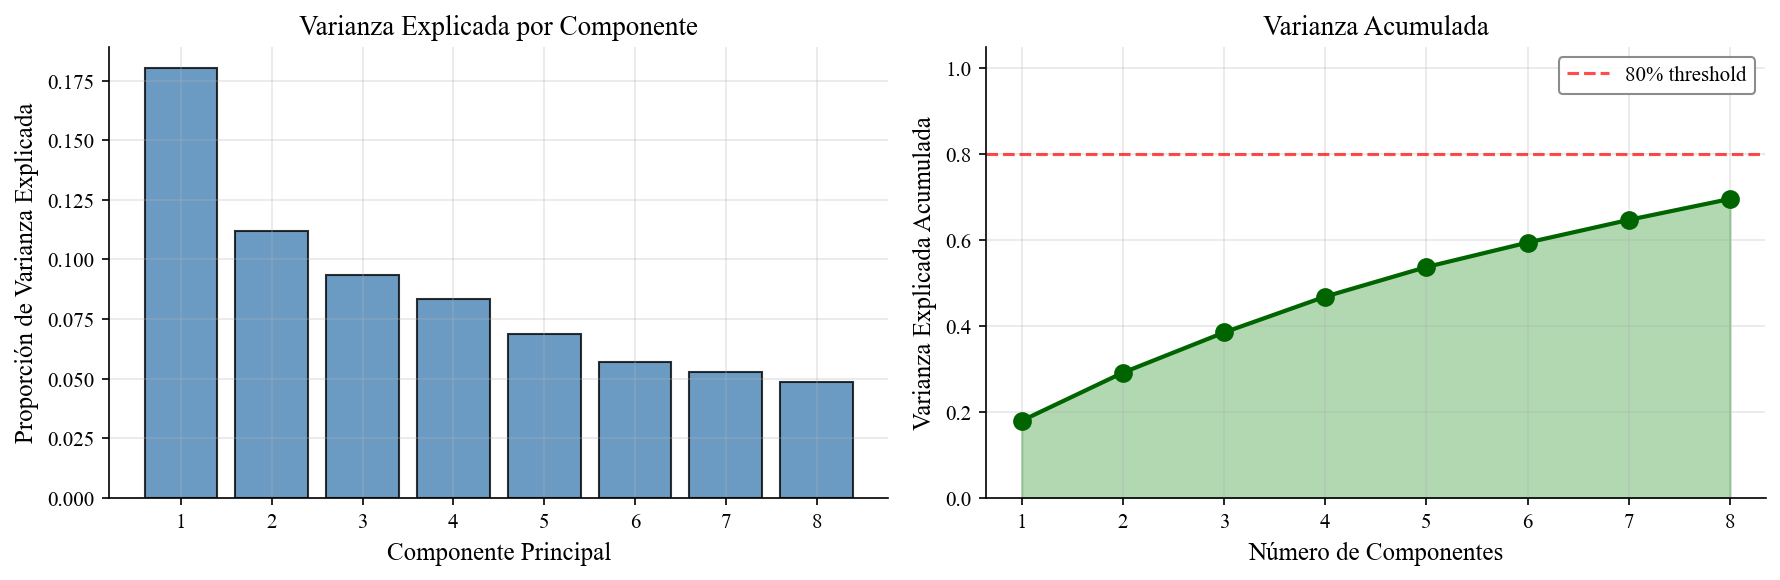


Varianza explicada por componente:
  PC1: 18.01%
  PC2: 11.19%
  PC3: 9.36%
  PC4: 8.35%
  PC5: 6.88%
  PC6: 5.69%
  PC7: 5.28%
  PC8: 4.87%

Varianza total explicada: 69.64%
Dimensiones reducidas: 42 → 8


In [13]:
# =============================================================================
# REDUCCIÓN DE DIMENSIONALIDAD CON PCA
# =============================================================================

# Número de componentes principales = número de qubits
n_components = 8
n_qubits = n_components

# Aplicamos PCA sobre los datos preprocesados (numéricas + one-hot)
pca = PCA(n_components=n_components, random_state=rs)

# Ajustamos SOLO con datos de train
X_train_pca = pca.fit_transform(X_train_preprocessed)
X_val_pca = pca.transform(X_val_preprocessed)
X_test_pca = pca.transform(X_test_preprocessed)

# Visualización de la varianza explicada
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Varianza explicada por componente
axes[0].bar(range(1, n_components+1), pca.explained_variance_ratio_, 
            color='steelblue', edgecolor='black', alpha=0.8)
axes[0].set_xlabel('Componente Principal')
axes[0].set_ylabel('Proporción de Varianza Explicada')
axes[0].set_title('Varianza Explicada por Componente')
axes[0].set_xticks(range(1, n_components+1))

# Varianza acumulada
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
axes[1].plot(range(1, n_components+1), cumulative_variance, 'o-', 
             color='darkgreen', linewidth=2, markersize=8)
axes[1].axhline(y=0.8, color='red', linestyle='--', alpha=0.7, label='80% threshold')
axes[1].fill_between(range(1, n_components+1), cumulative_variance, alpha=0.3, color='green')
axes[1].set_xlabel('Número de Componentes')
axes[1].set_ylabel('Varianza Explicada Acumulada')
axes[1].set_title('Varianza Acumulada')
axes[1].set_xticks(range(1, n_components+1))
axes[1].set_ylim(0, 1.05)
axes[1].legend()

plt.tight_layout()
plt.savefig('pca_variance.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"\nVarianza explicada por componente:")
for i, var in enumerate(pca.explained_variance_ratio_):
    print(f"  PC{i+1}: {var:.2%}")
print(f"\nVarianza total explicada: {cumulative_variance[-1]:.2%}")
print(f"Dimensiones reducidas: {X_train_preprocessed.shape[1]} → {n_components}")


In [14]:
# =============================================================================
# RE-ESCALADO POST-PCA A [0, π]
# =============================================================================

# PCA puede producir valores fuera de [0, π], así que re-escalamos
scaler_pca = MinMaxScaler(feature_range=(0, np.pi))

X_train_final = scaler_pca.fit_transform(X_train_pca)
X_val_final = scaler_pca.transform(X_val_pca)
X_test_final = scaler_pca.transform(X_test_pca)

print(f"Shape final de los datos:")
print(f"  - X_train: {X_train_final.shape}")
print(f"  - X_val:   {X_val_final.shape}")
print(f"  - X_test:  {X_test_final.shape}")
print(f"\nRango: [{X_train_final.min():.4f}, {X_train_final.max():.4f}]")


Shape final de los datos:
  - X_train: (441, 8)
  - X_val:   (111, 8)
  - X_test:  (138, 8)

Rango: [0.0000, 3.1416]


In [15]:
# =============================================================================
# CREACIÓN DE DATASETS PARA PYTORCH
# =============================================================================

# Encapsulamos los datos en NumpyDataset (de minitorch) para usar con PyTorch
tr_data = NumpyDataset(X_train_final, y_train)
val_data = NumpyDataset(X_val_final, y_val)
test_data = NumpyDataset(X_test_final, y_test)

print("Datasets creados para PyTorch:")
print(f"  - tr_data:   {len(tr_data)} muestras")
print(f"  - val_data:  {len(val_data)} muestras")
print(f"  - test_data: {len(test_data)} muestras")
print(f"\nShape de tensores: X={tr_data.x.shape}, y={tr_data.y.shape}")


Datasets creados para PyTorch:
  - tr_data:   441 muestras
  - val_data:  111 muestras
  - test_data: 138 muestras

Shape de tensores: X=torch.Size([441, 8]), y=torch.Size([441, 1])


---

<a name="2a-qsvm"></a>
## 2.A) Quantum Support Vector Machine (QSVM)

### Fundamento Teórico

Las **Quantum Support Vector Machines** utilizan un **kernel cuántico** para medir la similitud entre puntos de datos. El kernel cuántico aprovecha el espacio de Hilbert exponencialmente grande para crear separaciones no lineales.

**Proceso:**
1. **Codificación:** Cada punto de datos $\mathbf{x}$ se codifica en un estado cuántico $|\phi(\mathbf{x})\rangle$ usando *Angle Embedding*.
2. **Kernel:** El kernel cuántico calcula el producto interno:
   $$K(\mathbf{x}_1, \mathbf{x}_2) = |\langle\phi(\mathbf{x}_1)|\phi(\mathbf{x}_2)\rangle|^2$$
3. **SVM:** La matriz de kernel se pasa a un SVM clásico para encontrar el hiperplano óptimo.

**Ventaja teórica:** En algunos casos, los kernels cuánticos pueden capturar patrones que serían exponencialmente costosos de computar clásicamente.


In [16]:
# =============================================================================
# DEFINICIÓN DEL KERNEL CUÁNTICO
# =============================================================================

# Dispositivo cuántico con 4 qubits
dev_kernel = qml.device("default.qubit", wires=n_qubits)

@qml.qnode(dev_kernel)
def quantum_kernel(x1, x2):
    """
    Kernel cuántico que calcula el solapamiento entre dos estados codificados.
    
    El circuito:
    1. Aplica AngleEmbedding para codificar x1 (rotaciones RY)
    2. Aplica el adjunto (inverso) de AngleEmbedding para x2
    3. Mide la probabilidad de volver al estado |0000⟩
    
    Si x1 == x2, el circuito vuelve exactamente a |0000⟩ (prob = 1)
    Si x1 != x2, la probabilidad de |0000⟩ es menor
    """
    # Codificamos x1 con rotaciones RY
    qml.templates.AngleEmbedding(x1, wires=range(n_qubits))
    
    # Aplicamos el adjunto (inverso) de la codificación de x2
    # Esto "deshace" la rotación si x1 ≈ x2
    qml.adjoint(qml.templates.AngleEmbedding(x2, wires=range(n_qubits)))
    
    # Retornamos las probabilidades de cada estado computacional
    return qml.probs()

# Visualizamos el circuito del kernel
print("Circuito del Kernel Cuántico:")
print("="*50)
x_example = X_train_final[0]
print(qml.draw(quantum_kernel)(x_example, x_example))


Circuito del Kernel Cuántico:
0: ─╭AngleEmbedding(M0)─╭AngleEmbedding(M0)†─┤  Probs
1: ─├AngleEmbedding(M0)─├AngleEmbedding(M0)†─┤  Probs
2: ─├AngleEmbedding(M0)─├AngleEmbedding(M0)†─┤  Probs
3: ─├AngleEmbedding(M0)─├AngleEmbedding(M0)†─┤  Probs
4: ─├AngleEmbedding(M0)─├AngleEmbedding(M0)†─┤  Probs
5: ─├AngleEmbedding(M0)─├AngleEmbedding(M0)†─┤  Probs
6: ─├AngleEmbedding(M0)─├AngleEmbedding(M0)†─┤  Probs
7: ─╰AngleEmbedding(M0)─╰AngleEmbedding(M0)†─┤  Probs

M0 = 
[2.5089529  1.8790655  0.53669287 0.51072771 2.05308786 2.01478768
 1.05212029 1.55336954]


In [17]:
# =============================================================================
# FUNCIÓN PARA CALCULAR LA MATRIZ DE KERNEL
# =============================================================================

def kernel_matrix(A, B):
    """
    Calcula la matriz de Gram del kernel cuántico.
    
    K[i,j] = quantum_kernel(A[i], B[j])[0]
    
    Donde [0] selecciona la probabilidad del estado |0000⟩
    """
    return np.array([[quantum_kernel(a, b)[0] for b in B] for a in A])

# Test del kernel: K(x, x) debe ser ≈ 1
test_kernel = quantum_kernel(X_train_final[0], X_train_final[0])[0]
print(f"Test del kernel K(x, x): {test_kernel:.6f} (esperado: 1.0)")

test_kernel_diff = quantum_kernel(X_train_final[0], X_train_final[1])[0]
print(f"Test del kernel K(x1, x2): {test_kernel_diff:.6f} (esperado: < 1.0)")


Test del kernel K(x, x): 1.000000 (esperado: 1.0)
Test del kernel K(x1, x2): 0.369017 (esperado: < 1.0)


In [18]:
# =============================================================================
# Entrenamiento y evaluación de QSVM
# =============================================================================


print("\nEntrenando QSVM final con conjunto COMPLETO...")
start_time = time.time()
qsvm = SVC(kernel=kernel_matrix)
qsvm.fit(X_train_final, y_train)
qsvm_train_time = time.time() - start_time

# Predicciones
y_pred_qsvm = qsvm.predict(X_test_final)

# Métricas completas
qsvm_accuracy = accuracy_score(y_test, y_pred_qsvm)
qsvm_precision = precision_score(y_test, y_pred_qsvm)
qsvm_recall = recall_score(y_test, y_pred_qsvm)
qsvm_f1 = f1_score(y_test, y_pred_qsvm)

print("="*60)
print("RESULTADOS QSVM (CONJUNTO COMPLETO)")
print("="*60)
print(f"Muestras de entrenamiento: {len(X_train_final)}")
print(f"Accuracy:  {qsvm_accuracy:.4f}")
print(f"Precision: {qsvm_precision:.4f}")
print(f"Recall:    {qsvm_recall:.4f}")
print(f"F1-Score:  {qsvm_f1:.4f}")
print(f"\nTiempo de entrenamiento: {qsvm_train_time:.2f}s")

# Guardamos resultados para comparación final
results = {
    'QSVM': {
        'accuracy': qsvm_accuracy,
        'precision': qsvm_precision,
        'recall': qsvm_recall,
        'f1': qsvm_f1,
        'time': qsvm_train_time,
        'params': 'N/A',
        'y_pred': y_pred_qsvm,
        'y_proba': None  # SVM no da probabilidades directamente
    }
}



Entrenando QSVM final con conjunto COMPLETO...
RESULTADOS QSVM (CONJUNTO COMPLETO)
Muestras de entrenamiento: 441
Accuracy:  0.7826
Precision: 0.7013
Recall:    0.8852
F1-Score:  0.7826

Tiempo de entrenamiento: 462.62s


---

<a name="2b-qnn"></a>
## 2.B) Red Neuronal Cuántica (QNN)

### Fundamento Teórico

La **Red Neuronal Cuántica** (QNN - Quantum Neural Network) es un modelo que utiliza únicamente un circuito cuántico parametrizado para aprender una función de clasificación.

**Arquitectura:**
1. **Feature Map (Codificación):** Los datos clásicos se codifican en estados cuánticos usando *Angle Embedding* ($R_Y(\theta_i)$).
2. **Ansatz Variacional:** Capas de puertas parametrizadas (*StronglyEntanglingLayers*) que crean entrelazamiento y transformaciones.
3. **Medición:** Usamos el operador Hermitiano $|0\rangle\langle0|$ para medir la probabilidad de estar en el estado $|0\rangle$.

**Fórmula del circuito:**
$$|\psi(\mathbf{x}, \boldsymbol{\theta})\rangle = U(\boldsymbol{\theta}) \cdot U_\phi(\mathbf{x}) |0\rangle^{\otimes n}$$

**Problema de Barren Plateaus:** Los gradientes pueden desvanecerse exponencialmente con el número de qubits, dificultando el entrenamiento. Se mitiga usando pocas capas y circuitos estructurados.


In [ ]:
# =============================================================================
# DEFINICIÓN DEL CIRCUITO QNN (Red Neuronal Cuántica)
# =============================================================================

# Dispositivo cuántico para QNN
dev_qnn = qml.device("default.qubit", wires=n_qubits)

@qml.qnode(dev_qnn)
def qnn_circuit(inputs, weights):
    """
    Circuito de Red Neuronal Cuántica para clasificación binaria.
    
    Basado en PL11 - Quantum Neural Networks.
    
    Args:
        inputs: Features de entrada (4 valores en [0, π])
        weights: Parámetros entrenables del ansatz variacional
    
    Returns:
        Valor esperado del proyector |0⟩⟨0| en el primer qubit
    """
    # Feature Map: Angle Embedding codifica cada feature como rotación RY
    qml.templates.AngleEmbedding(inputs, wires=range(n_qubits))
    
    # Ansatz Variacional: StronglyEntanglingLayers
    # Incluye rotaciones Rot(φ, θ, ω) y CNOTs para entrelazamiento
    qml.templates.StronglyEntanglingLayers(weights, wires=range(n_qubits))
    
    # Medición: Proyector sobre |0⟩ en el primer qubit (según PL11)
    # Esto da un valor entre 0 y 1, ideal para clasificación binaria
    state_0 = [[1], [0]]
    projector = state_0 * np.conj(state_0).T  # |0⟩⟨0|
    return [qml.expval(qml.Hermitian(projector, wires=[0]))]

# Visualizamos el circuito (con 1 capa)
print("Circuito QNN (1 capa variacional):")
print("="*50)
example_weights = np.random.random((1, n_qubits, 3))
print(qml.draw(qnn_circuit)(X_train_final[0], example_weights))


Circuito QNN (1 capa variacional):
0: ─╭AngleEmbedding(M0)─╭StronglyEntanglingLayers(M1)─┤  <𝓗(M2)>
1: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤         
2: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤         
3: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤         
4: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤         
5: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤         
6: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤         
7: ─╰AngleEmbedding(M0)─╰StronglyEntanglingLayers(M1)─┤         

M0 = 
[2.5089529  1.8790655  0.53669287 0.51072771 2.05308786 2.01478768
 1.05212029 1.55336954]
M1 = 
[[[7.79691000e-01 5.96850158e-01 4.45832753e-01]
  [9.99749158e-02 4.59248892e-01 3.33708611e-01]
  [1.42866818e-01 6.50888473e-01 5.64115790e-02]
  [7.21998772e-01 9.38552709e-01 7.78765841e-04]
  [9.92211559e-01 6.17481510e-01 6.11653160e-01]
  [7.06630522e-03 2.30624250e-02 5.24774660e-01]
  [3.99860972e-01 4.66656632e-02 9.73755519e-01

### Búsqueda de Hiperparámetros

Antes de entrenar los modelos definitivos, realizamos una búsqueda de hiperparámetros para encontrar la mejor combinación de:
- **Learning rate**: Velocidad de aprendizaje del optimizador
- **Número de capas variacionales**: Expresividad del circuito cuántico

Usamos validación para seleccionar los mejores hiperparámetros.


In [ ]:
# =============================================================================
# BÚSQUEDA DE HIPERPARÁMETROS PARA QNN
# =============================================================================

def train_qnn_with_params(n_layers, lr, max_epochs=50, patience=8, verbose=False):
    """
    Entrena una QNN con hiperparámetros específicos y retorna métricas de validación.
    """
    set_seed(rs)
    
    # Crear circuito y modelo
    weight_shapes = {"weights": (n_layers, n_qubits, 3)}
    qlayer = qml.qnn.TorchLayer(qnn_circuit, weight_shapes)
    model = nn.Sequential(qlayer)
    
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    
    # Entrenamiento silencioso
    tr_losses, val_losses = [], []
    best_val_loss = float('inf')
    epochs_no_improve = 0
    
    for epoch in range(max_epochs):
        # Forward pass
        opt.zero_grad()
        loss_val = F.binary_cross_entropy(model(tr_data.x), tr_data.y)
        loss_val.backward()
        opt.step()
        
        tr_losses.append(float(loss_val.detach()))
        
        with torch.no_grad():
            val_loss = float(F.binary_cross_entropy(model(val_data.x), val_data.y))
            val_losses.append(val_loss)
        
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
        
        if epochs_no_improve >= patience:
            break
    
    # Evaluar en validación
    with torch.no_grad():
        y_pred_val = (model(val_data.x).numpy() >= 0.5).astype(int).flatten()
    
    val_f1 = f1_score(y_val, y_pred_val)
    val_acc = accuracy_score(y_val, y_pred_val)
    
    return {
        'n_layers': n_layers,
        'lr': lr,
        'val_f1': val_f1,
        'val_acc': val_acc,
        'epochs': len(tr_losses),
        'best_val_loss': best_val_loss
    }

# Grid de hiperparámetros
learning_rates = [0.01, 0.05, 0.1, 0.2]
n_layers_options = [1, 2, 3]

print("="*70)
print("BÚSQUEDA DE HIPERPARÁMETROS QNN")
print("="*70)
print(f"Learning rates: {learning_rates}")
print(f"Capas variacionales: {n_layers_options}")
print(f"Total combinaciones: {len(learning_rates) * len(n_layers_options)}")
print("-"*70)

qnn_search_results = []
best_qnn_f1 = 0
best_qnn_params = {}

for n_layers in n_layers_options:
    for lr in learning_rates:
        print(f"Probando: n_layers={n_layers}, lr={lr}...", end=" ")
        result = train_qnn_with_params(n_layers, lr)
        qnn_search_results.append(result)
        
        print(f"Val F1: {result['val_f1']:.4f}, Epochs: {result['epochs']}")
        
        if result['val_f1'] > best_qnn_f1:
            best_qnn_f1 = result['val_f1']
            best_qnn_params = {'n_layers': n_layers, 'lr': lr}

print("-"*70)
print(f"\n✓ MEJORES HIPERPARÁMETROS QNN:")
print(f"  Capas: {best_qnn_params['n_layers']}")
print(f"  Learning rate: {best_qnn_params['lr']}")
print(f"  Validation F1: {best_qnn_f1:.4f}")


BÚSQUEDA DE HIPERPARÁMETROS QNN
Learning rates: [0.01, 0.05, 0.1, 0.2]
Capas variacionales: [1, 2, 3]
Total combinaciones: 12
----------------------------------------------------------------------
Probando: n_layers=1, lr=0.01... Val F1: 0.4808, Epochs: 50
Probando: n_layers=1, lr=0.05... Val F1: 0.4554, Epochs: 17
Probando: n_layers=1, lr=0.1... Val F1: 0.4810, Epochs: 47
Probando: n_layers=1, lr=0.2... Val F1: 0.5641, Epochs: 33
Probando: n_layers=2, lr=0.01... Val F1: 0.4954, Epochs: 9
Probando: n_layers=2, lr=0.05... Val F1: 0.4771, Epochs: 9
Probando: n_layers=2, lr=0.1... Val F1: 0.4536, Epochs: 9
Probando: n_layers=2, lr=0.2... Val F1: 0.8333, Epochs: 32
Probando: n_layers=3, lr=0.01... Val F1: 0.8182, Epochs: 50
Probando: n_layers=3, lr=0.05... Val F1: 0.8132, Epochs: 45
Probando: n_layers=3, lr=0.1... Val F1: 0.8000, Epochs: 31
Probando: n_layers=3, lr=0.2... Val F1: 0.7957, Epochs: 32
----------------------------------------------------------------------

✓ MEJORES HIPERPARÁM

In [ ]:
# =============================================================================
# BÚSQUEDA DE HIPERPARÁMETROS PARA RED HÍBRIDA
# =============================================================================

# Dispositivo cuántico para modelo híbrido
dev_hybrid = qml.device("default.qubit", wires=n_qubits)

@qml.qnode(dev_hybrid)
def hybrid_circuit(inputs, weights):
    """
    Circuito cuántico para red híbrida.
    
    A diferencia de la QNN, este circuito:
    - Recibe inputs preprocesados por capa clásica
    - Retorna valores esperados de PauliZ en cada qubit (no solo el primero)
    
    Returns:
        Lista de valores esperados de σz en cada qubit (valores en [-1, 1])
    """
    # Feature Map
    qml.templates.AngleEmbedding(inputs, wires=range(n_qubits))
    
    # Ansatz Variacional
    qml.templates.StronglyEntanglingLayers(weights, wires=range(n_qubits))
    
    # Medición: valor esperado de PauliZ en cada qubit
    # Esto da n_qubits valores que la capa clásica posterior puede combinar
    return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

def train_hybrid_with_params(n_layers, lr, max_epochs=50, patience=8):
    """
    Entrena una red híbrida con hiperparámetros específicos.
    """
    set_seed(rs)
    
    # Crear modelo híbrido
    weight_shapes = {"weights": (n_layers, n_qubits, 3)}
    qlayer = qml.qnn.TorchLayer(hybrid_circuit, weight_shapes)
    
    model = nn.Sequential(
        nn.Linear(n_qubits, n_qubits),
        nn.ReLU(),
        qlayer,
        nn.Linear(n_qubits, 1),
        nn.Sigmoid()
    )
    
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    
    # Entrenamiento silencioso
    best_val_loss = float('inf')
    epochs_no_improve = 0
    
    for epoch in range(max_epochs):
        opt.zero_grad()
        loss_val = F.binary_cross_entropy(model(tr_data.x), tr_data.y)
        loss_val.backward()
        opt.step()
        
        with torch.no_grad():
            val_loss = float(F.binary_cross_entropy(model(val_data.x), val_data.y))
        
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
        
        if epochs_no_improve >= patience:
            break
    
    # Evaluar en validación
    with torch.no_grad():
        y_pred_val = (model(val_data.x).numpy() >= 0.5).astype(int).flatten()
    
    val_f1 = f1_score(y_val, y_pred_val)
    val_acc = accuracy_score(y_val, y_pred_val)
    
    return {
        'n_layers': n_layers,
        'lr': lr,
        'val_f1': val_f1,
        'val_acc': val_acc,
        'epochs': epoch + 1,
        'best_val_loss': best_val_loss
    }

print("\n" + "="*70)
print("BÚSQUEDA DE HIPERPARÁMETROS RED HÍBRIDA")
print("="*70)
print(f"Learning rates: {learning_rates}")
print(f"Capas variacionales: {n_layers_options}")
print(f"Total combinaciones: {len(learning_rates) * len(n_layers_options)}")
print("-"*70)

hybrid_search_results = []
best_hybrid_f1 = 0
best_hybrid_params = {}

for n_layers in n_layers_options:
    for lr in learning_rates:
        print(f"Probando: n_layers={n_layers}, lr={lr}...", end=" ")
        result = train_hybrid_with_params(n_layers, lr)
        hybrid_search_results.append(result)
        
        print(f"Val F1: {result['val_f1']:.4f}, Epochs: {result['epochs']}")
        
        if result['val_f1'] > best_hybrid_f1:
            best_hybrid_f1 = result['val_f1']
            best_hybrid_params = {'n_layers': n_layers, 'lr': lr}

print("-"*70)
print(f"\n✓ MEJORES HIPERPARÁMETROS HÍBRIDO:")
print(f"  Capas: {best_hybrid_params['n_layers']}")
print(f"  Learning rate: {best_hybrid_params['lr']}")
print(f"  Validation F1: {best_hybrid_f1:.4f}")



BÚSQUEDA DE HIPERPARÁMETROS RED HÍBRIDA
Learning rates: [0.01, 0.05, 0.1, 0.2]
Capas variacionales: [1, 2, 3]
Total combinaciones: 12
----------------------------------------------------------------------
Probando: n_layers=1, lr=0.01... Val F1: 0.8400, Epochs: 50
Probando: n_layers=1, lr=0.05... Val F1: 0.8515, Epochs: 36
Probando: n_layers=1, lr=0.1... Val F1: 0.8247, Epochs: 25
Probando: n_layers=1, lr=0.2... Val F1: 0.7333, Epochs: 35
Probando: n_layers=2, lr=0.01... Val F1: 0.7742, Epochs: 50
Probando: n_layers=2, lr=0.05... Val F1: 0.8515, Epochs: 41
Probando: n_layers=2, lr=0.1... Val F1: 0.8600, Epochs: 36
Probando: n_layers=2, lr=0.2... Val F1: 0.8600, Epochs: 43
Probando: n_layers=3, lr=0.01... Val F1: 0.7955, Epochs: 50
Probando: n_layers=3, lr=0.05... Val F1: 0.8600, Epochs: 38
Probando: n_layers=3, lr=0.1... Val F1: 0.8515, Epochs: 25
Probando: n_layers=3, lr=0.2... Val F1: 0.8713, Epochs: 35
----------------------------------------------------------------------

✓ MEJORE

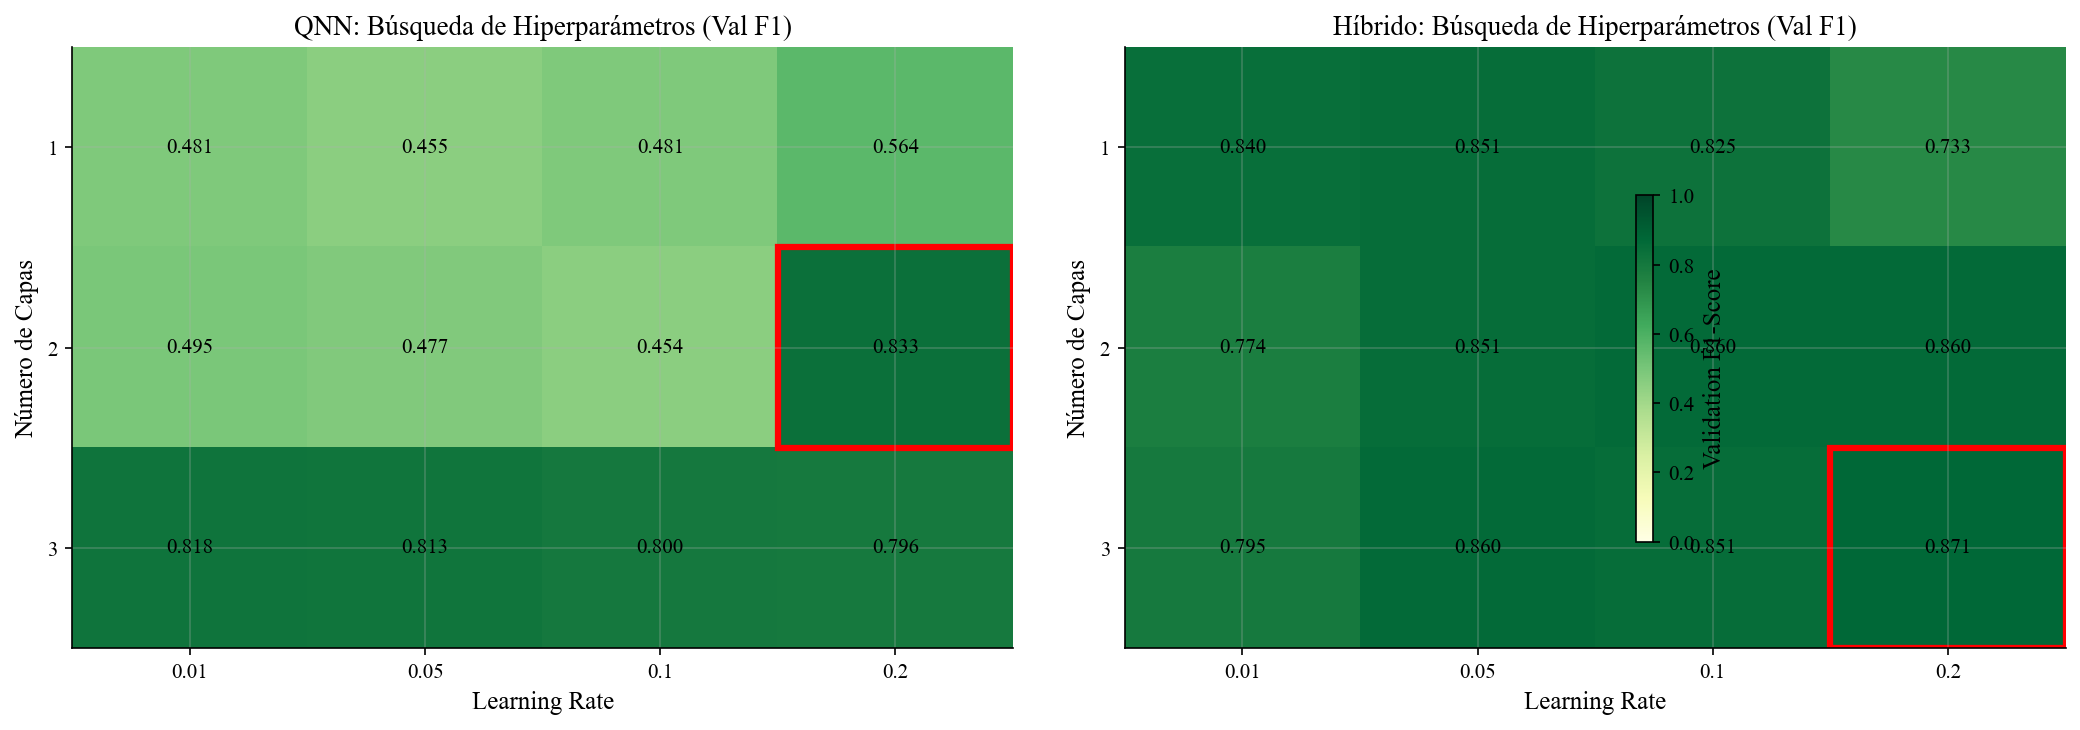


RESUMEN DE BÚSQUEDA DE HIPERPARÁMETROS

QNN óptimo:     2 capas, lr=0.2 → F1=0.8333
Híbrido óptimo: 3 capas, lr=0.2 → F1=0.8713


In [ ]:
# =============================================================================
# VISUALIZACIÓN DE RESULTADOS DE BÚSQUEDA
# =============================================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Preparar datos para heatmaps
def create_heatmap_data(results, n_layers_opts, lr_opts):
    heatmap = np.zeros((len(n_layers_opts), len(lr_opts)))
    for r in results:
        i = n_layers_opts.index(r['n_layers'])
        j = lr_opts.index(r['lr'])
        heatmap[i, j] = r['val_f1']
    return heatmap

# Heatmap QNN
qnn_heatmap = create_heatmap_data(qnn_search_results, n_layers_options, learning_rates)
im1 = axes[0].imshow(qnn_heatmap, cmap='YlGn', aspect='auto', vmin=0, vmax=1)
axes[0].set_xticks(range(len(learning_rates)))
axes[0].set_xticklabels([str(lr) for lr in learning_rates])
axes[0].set_yticks(range(len(n_layers_options)))
axes[0].set_yticklabels([str(n) for n in n_layers_options])
axes[0].set_xlabel('Learning Rate')
axes[0].set_ylabel('Número de Capas')
axes[0].set_title('QNN: Búsqueda de Hiperparámetros (Val F1)')

# Añadir valores
for i in range(len(n_layers_options)):
    for j in range(len(learning_rates)):
        text = axes[0].text(j, i, f'{qnn_heatmap[i, j]:.3f}',
                           ha="center", va="center", color="black", fontsize=10)

# Marcar mejor combinación
best_i = n_layers_options.index(best_qnn_params['n_layers'])
best_j = learning_rates.index(best_qnn_params['lr'])
axes[0].add_patch(plt.Rectangle((best_j-0.5, best_i-0.5), 1, 1, 
                                  fill=False, edgecolor='red', linewidth=3))

# Heatmap Híbrido
hybrid_heatmap = create_heatmap_data(hybrid_search_results, n_layers_options, learning_rates)
im2 = axes[1].imshow(hybrid_heatmap, cmap='YlGn', aspect='auto', vmin=0, vmax=1)
axes[1].set_xticks(range(len(learning_rates)))
axes[1].set_xticklabels([str(lr) for lr in learning_rates])
axes[1].set_yticks(range(len(n_layers_options)))
axes[1].set_yticklabels([str(n) for n in n_layers_options])
axes[1].set_xlabel('Learning Rate')
axes[1].set_ylabel('Número de Capas')
axes[1].set_title('Híbrido: Búsqueda de Hiperparámetros (Val F1)')

# Añadir valores
for i in range(len(n_layers_options)):
    for j in range(len(learning_rates)):
        text = axes[1].text(j, i, f'{hybrid_heatmap[i, j]:.3f}',
                           ha="center", va="center", color="black", fontsize=10)

# Marcar mejor combinación
best_i = n_layers_options.index(best_hybrid_params['n_layers'])
best_j = learning_rates.index(best_hybrid_params['lr'])
axes[1].add_patch(plt.Rectangle((best_j-0.5, best_i-0.5), 1, 1, 
                                  fill=False, edgecolor='red', linewidth=3))

plt.colorbar(im2, ax=axes, shrink=0.6, label='Validation F1-Score')
plt.tight_layout()
plt.savefig('hyperparameter_search.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n" + "="*70)
print("RESUMEN DE BÚSQUEDA DE HIPERPARÁMETROS")
print("="*70)
print(f"\nQNN óptimo:     {best_qnn_params['n_layers']} capas, lr={best_qnn_params['lr']} → F1={best_qnn_f1:.4f}")
print(f"Híbrido óptimo: {best_hybrid_params['n_layers']} capas, lr={best_hybrid_params['lr']} → F1={best_hybrid_f1:.4f}")


### Entrenamiento Definitivo con Mejores Hiperparámetros

Ahora entrenamos los modelos QNN e Híbridos usando los hiperparámetros óptimos encontrados en la búsqueda.


### QNN con Hiperparámetros Óptimos

Usamos los mejores hiperparámetros encontrados en la búsqueda (número de capas y learning rate).


In [ ]:
# =============================================================================
# QNN CON MEJORES HIPERPARÁMETROS (de búsqueda)
# =============================================================================

# Reiniciamos la semilla para reproducibilidad
set_seed(rs)

# Usamos los mejores hiperparámetros encontrados en la búsqueda
n_layers_qnn_best = best_qnn_params['n_layers']
lr_qnn_best = best_qnn_params['lr']

print("="*60)
print("QNN CON HIPERPARÁMETROS ÓPTIMOS")
print("="*60)
print(f"Capas variacionales: {n_layers_qnn_best}")
print(f"Learning rate: {lr_qnn_best}")
print("-"*60)

# Definimos la forma de los pesos
weight_shapes_qnn_best = {"weights": (n_layers_qnn_best, n_qubits, 3)}

# Creamos la capa cuántica compatible con PyTorch
qlayer_qnn_best = qml.qnn.TorchLayer(qnn_circuit, weight_shapes_qnn_best)

# El modelo es solo la capa cuántica (QNN pura)
model_qnn_best = nn.Sequential(qlayer_qnn_best)

# Optimizador con learning rate óptimo de la búsqueda
opt_qnn_best = torch.optim.Adam(model_qnn_best.parameters(), lr=lr_qnn_best)
loss_fn = F.binary_cross_entropy

# Mostramos resumen del modelo
print(f"\nParámetros entrenables: {n_layers_qnn_best * n_qubits * 3}")
summary(model_qnn_best)


QNN CON HIPERPARÁMETROS ÓPTIMOS
Capas variacionales: 2
Learning rate: 0.2
------------------------------------------------------------

Parámetros entrenables: 48


Layer (type:depth-idx)                   Param #
Sequential                               --
├─TorchLayer: 1-1                        48
Total params: 48
Trainable params: 48
Non-trainable params: 0

In [ ]:
# =============================================================================
# ENTRENAMIENTO QNN (HIPERPARÁMETROS ÓPTIMOS)
# =============================================================================

print(f"Entrenando QNN con {n_layers_qnn_best} capa(s) variacional(es)...")
print("="*60)

start_time = time.time()
history_qnn_best = train(
    model=model_qnn_best, 
    loss=loss_fn, 
    opt=opt_qnn_best, 
    tr_data=tr_data, 
    val_data=val_data, 
    max_epochs=150,
    patience=15
)
qnn_best_train_time = time.time() - start_time

print(f"\nTiempo total de entrenamiento: {qnn_best_train_time:.2f} segundos")


Entrenando QNN con 2 capa(s) variacional(es)...
Epoch 1 | Train loss: 0.6731 | Valid loss: 0.7185
Epoch 2 | Train loss: 0.6583 | Valid loss: 0.7301
Epoch 3 | Train loss: 0.653 | Valid loss: 0.7255
Epoch 4 | Train loss: 0.651 | Valid loss: 0.7237
Epoch 5 | Train loss: 0.6482 | Valid loss: 0.7251
Epoch 6 | Train loss: 0.6446 | Valid loss: 0.7252
Epoch 7 | Train loss: 0.6405 | Valid loss: 0.7203
Epoch 8 | Train loss: 0.6382 | Valid loss: 0.7103
Epoch 9 | Train loss: 0.6357 | Valid loss: 0.6982
Epoch 10 | Train loss: 0.6295 | Valid loss: 0.6833
Epoch 11 | Train loss: 0.6198 | Valid loss: 0.6633
Epoch 12 | Train loss: 0.6031 | Valid loss: 0.6341
Epoch 13 | Train loss: 0.5769 | Valid loss: 0.5942
Epoch 14 | Train loss: 0.5496 | Valid loss: 0.553
Epoch 15 | Train loss: 0.5303 | Valid loss: 0.5221
Epoch 16 | Train loss: 0.5212 | Valid loss: 0.5038
Epoch 17 | Train loss: 0.5208 | Valid loss: 0.4973
Epoch 18 | Train loss: 0.5279 | Valid loss: 0.5016
Epoch 19 | Train loss: 0.5357 | Valid loss: 0.

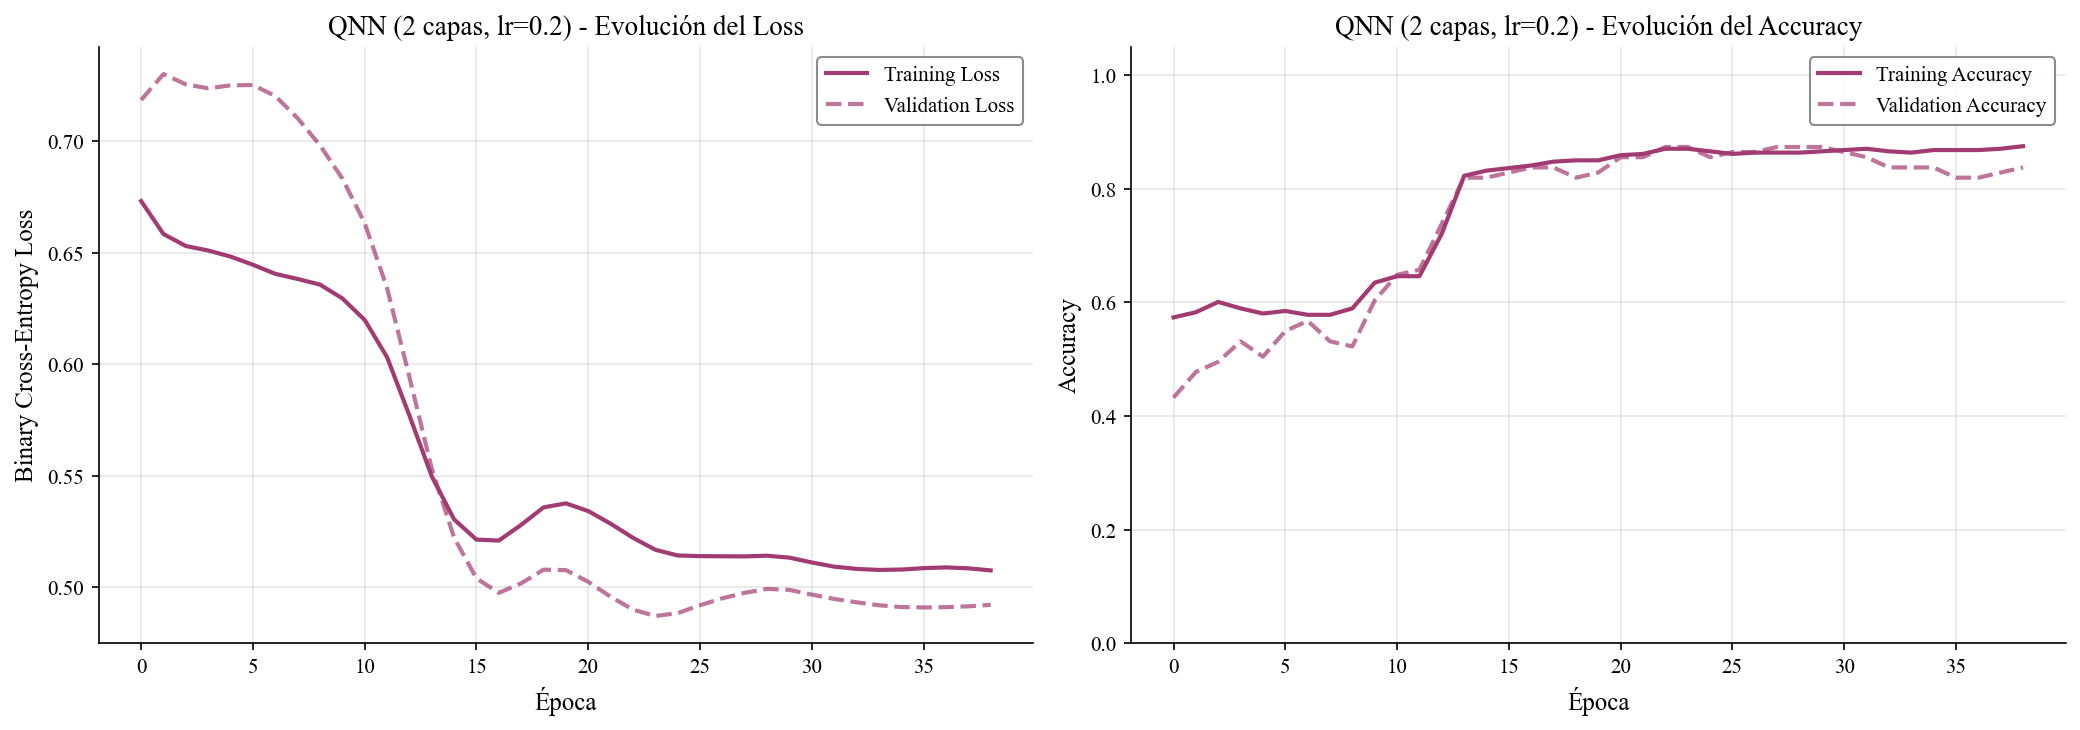

In [ ]:
# =============================================================================
# GRÁFICAS DE ENTRENAMIENTO QNN (ÓPTIMO)
# =============================================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfica de Loss
axes[0].plot(history_qnn_best.tr_losses, label='Training Loss', color=COLORS['qnn_1'], linewidth=2)
axes[0].plot(history_qnn_best.val_losses, label='Validation Loss', color=COLORS['qnn_1'], 
             linestyle='--', linewidth=2, alpha=0.7)
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Binary Cross-Entropy Loss')
axes[0].set_title(f'QNN ({n_layers_qnn_best} capas, lr={lr_qnn_best}) - Evolución del Loss')
axes[0].legend()

# Gráfica de Accuracy
axes[1].plot(history_qnn_best.tr_accuracy, label='Training Accuracy', color=COLORS['qnn_1'], linewidth=2)
axes[1].plot(history_qnn_best.val_accuracy, label='Validation Accuracy', color=COLORS['qnn_1'], 
             linestyle='--', linewidth=2, alpha=0.7)
axes[1].set_xlabel('Época')
axes[1].set_ylabel('Accuracy')
axes[1].set_title(f'QNN ({n_layers_qnn_best} capas, lr={lr_qnn_best}) - Evolución del Accuracy')
axes[1].legend()
axes[1].set_ylim(0, 1.05)

plt.tight_layout()
plt.savefig('qnn_training.png', dpi=300, bbox_inches='tight')
plt.show()


In [ ]:
# =============================================================================
# EVALUACIÓN QNN (ÓPTIMO)
# =============================================================================

# Predicciones en test
with torch.no_grad():
    y_proba_qnn_best = model_qnn_best(test_data.x).numpy().flatten()
    y_pred_qnn_best = (y_proba_qnn_best >= 0.5).astype(int)

# Métricas
qnn_best_accuracy = accuracy_score(y_test, y_pred_qnn_best)
qnn_best_precision = precision_score(y_test, y_pred_qnn_best)
qnn_best_recall = recall_score(y_test, y_pred_qnn_best)
qnn_best_f1 = f1_score(y_test, y_pred_qnn_best)

print("="*60)
print(f"RESULTADOS QNN ÓPTIMO ({n_layers_qnn_best} capas, lr={lr_qnn_best})")
print("="*60)
print(f"Accuracy:  {qnn_best_accuracy:.4f}")
print(f"Precision: {qnn_best_precision:.4f}")
print(f"Recall:    {qnn_best_recall:.4f}")
print(f"F1-Score:  {qnn_best_f1:.4f}")
print(f"\nParámetros entrenables: {n_layers_qnn_best * n_qubits * 3}")
print(f"Tiempo de entrenamiento: {qnn_best_train_time:.2f}s")

# Guardamos resultados
results['QNN (óptimo)'] = {
    'accuracy': qnn_best_accuracy,
    'precision': qnn_best_precision,
    'recall': qnn_best_recall,
    'f1': qnn_best_f1,
    'time': qnn_best_train_time,
    'params': n_layers_qnn_best * n_qubits * 3,
    'y_pred': y_pred_qnn_best,
    'y_proba': y_proba_qnn_best
}


RESULTADOS QNN ÓPTIMO (2 capas, lr=0.2)
Accuracy:  0.8116
Precision: 0.7536
Recall:    0.8525
F1-Score:  0.8000

Parámetros entrenables: 48
Tiempo de entrenamiento: 7.00s


---

<a name="2c-híbrido"></a>
## 2.C) Red Neuronal Híbrida (Clásica-Cuántica)

### Fundamento Teórico

Las **redes híbridas** combinan capas clásicas (fully connected) con capas cuánticas. Esta arquitectura ofrece varias ventajas:

1. **Preprocesamiento clásico:** Las capas clásicas pueden aprender transformaciones útiles antes del procesamiento cuántico.
2. **Postprocesamiento clásico:** Se puede ajustar la salida cuántica para la tarea específica.
3. **Flexibilidad:** Permite usar pocos qubits incluso con muchas features de entrada.

**Arquitectura:**
$$\text{Input} \xrightarrow{\text{Linear + ReLU}} \text{Capa Cuántica} \xrightarrow{\text{Linear + Sigmoid}} \text{Output}$$

**Medición:** A diferencia de la QNN, la capa cuántica retorna el valor esperado de $\sigma_z$ (PauliZ) en cada qubit, dando valores en $[-1, 1]$.


In [27]:
# =============================================================================
# DEFINICIÓN DEL CIRCUITO PARA RED HÍBRIDA
# =============================================================================

# Dispositivo cuántico para modelo híbrido
dev_hybrid = qml.device("default.qubit", wires=n_qubits)

@qml.qnode(dev_hybrid)
def hybrid_circuit(inputs, weights):
    """
    Circuito cuántico para red híbrida.
    
    A diferencia de la QNN, este circuito:
    - Recibe inputs preprocesados por capa clásica
    - Retorna valores esperados de PauliZ en cada qubit (no solo el primero)
    
    Returns:
        Lista de valores esperados de σz en cada qubit (valores en [-1, 1])
    """
    # Feature Map
    qml.templates.AngleEmbedding(inputs, wires=range(n_qubits))
    
    # Ansatz Variacional
    qml.templates.StronglyEntanglingLayers(weights, wires=range(n_qubits))
    
    # Medición: valor esperado de PauliZ en cada qubit
    # Esto da n_qubits valores que la capa clásica posterior puede combinar
    return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

# Visualizamos el circuito
print("Circuito para Red Híbrida:")
print("="*50)
example_weights = np.random.random((1, n_qubits, 3))
print(qml.draw(hybrid_circuit)(X_train_final[0], example_weights))


Circuito para Red Híbrida:
0: ─╭AngleEmbedding(M0)─╭StronglyEntanglingLayers(M1)─┤  <Z>
1: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤  <Z>
2: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤  <Z>
3: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤  <Z>
4: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤  <Z>
5: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤  <Z>
6: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─┤  <Z>
7: ─╰AngleEmbedding(M0)─╰StronglyEntanglingLayers(M1)─┤  <Z>

M0 = 
[2.5089529  1.8790655  0.53669287 0.51072771 2.05308786 2.01478768
 1.05212029 1.55336954]
M1 = 
[[[1.83434790e-01 7.79691000e-01 5.96850158e-01]
  [4.45832753e-01 9.99749158e-02 4.59248892e-01]
  [3.33708611e-01 1.42866818e-01 6.50888473e-01]
  [5.64115790e-02 7.21998772e-01 9.38552709e-01]
  [7.78765841e-04 9.92211559e-01 6.17481510e-01]
  [6.11653160e-01 7.06630522e-03 2.30624250e-02]
  [5.24774660e-01 3.99860972e-01 4.66656632e-02]
  [9.73755519e-01 2.32771340e-01 9.060

### Red Híbrida con Hiperparámetros Óptimos

Usamos los mejores hiperparámetros encontrados en la búsqueda (número de capas y learning rate).


In [28]:
# =============================================================================
# RED HÍBRIDA CON MEJORES HIPERPARÁMETROS (de búsqueda)
# =============================================================================

# Reiniciamos semilla
set_seed(rs)

# Usamos los mejores hiperparámetros encontrados en la búsqueda
n_layers_hybrid_best = best_hybrid_params['n_layers']
lr_hybrid_best = best_hybrid_params['lr']

print("="*60)
print("RED HÍBRIDA CON HIPERPARÁMETROS ÓPTIMOS")
print("="*60)
print(f"Capas variacionales: {n_layers_hybrid_best}")
print(f"Learning rate: {lr_hybrid_best}")
print("-"*60)

# Forma de los pesos cuánticos
weight_shapes_hybrid_best = {"weights": (n_layers_hybrid_best, n_qubits, 3)}

# Capa cuántica
qlayer_hybrid_best = qml.qnn.TorchLayer(hybrid_circuit, weight_shapes_hybrid_best)

# Arquitectura híbrida: Clásica -> Cuántica -> Clásica
model_hybrid_best = nn.Sequential(
    nn.Linear(n_qubits, n_qubits),
    nn.ReLU(),
    qlayer_hybrid_best,
    nn.Linear(n_qubits, 1),
    nn.Sigmoid()
)

# Optimizador con learning rate óptimo de la búsqueda
opt_hybrid_best = torch.optim.Adam(model_hybrid_best.parameters(), lr=lr_hybrid_best)

# Resumen del modelo
print(f"\nParámetros totales:")
summary(model_hybrid_best)


RED HÍBRIDA CON HIPERPARÁMETROS ÓPTIMOS
Capas variacionales: 3
Learning rate: 0.2
------------------------------------------------------------

Parámetros totales:


Layer (type:depth-idx)                   Param #
Sequential                               --
├─Linear: 1-1                            72
├─ReLU: 1-2                              --
├─TorchLayer: 1-3                        72
├─Linear: 1-4                            9
├─Sigmoid: 1-5                           --
Total params: 153
Trainable params: 153
Non-trainable params: 0

In [29]:
# =============================================================================
# ENTRENAMIENTO RED HÍBRIDA (HIPERPARÁMETROS ÓPTIMOS)
# =============================================================================

print(f"Entrenando Red Híbrida con {n_layers_hybrid_best} capa(s) variacional(es)...")
print("="*60)

start_time = time.time()
history_hybrid_best = train(
    model=model_hybrid_best, 
    loss=loss_fn, 
    opt=opt_hybrid_best, 
    tr_data=tr_data, 
    val_data=val_data, 
    max_epochs=150, 
    patience=15
)
hybrid_best_train_time = time.time() - start_time

print(f"\nTiempo total de entrenamiento: {hybrid_best_train_time:.2f} segundos")


Entrenando Red Híbrida con 3 capa(s) variacional(es)...
Epoch 1 | Train loss: 0.6882 | Valid loss: 0.6869
Epoch 2 | Train loss: 0.6904 | Valid loss: 0.6903
Epoch 3 | Train loss: 0.6914 | Valid loss: 0.6908
Epoch 4 | Train loss: 0.6889 | Valid loss: 0.6873
Epoch 5 | Train loss: 0.6858 | Valid loss: 0.6846
Epoch 6 | Train loss: 0.6796 | Valid loss: 0.6786
Epoch 7 | Train loss: 0.6717 | Valid loss: 0.6736
Epoch 8 | Train loss: 0.6746 | Valid loss: 0.6767
Epoch 9 | Train loss: 0.6273 | Valid loss: 0.6342
Epoch 10 | Train loss: 0.5914 | Valid loss: 0.5997
Epoch 11 | Train loss: 0.6198 | Valid loss: 0.6342
Epoch 12 | Train loss: 0.5726 | Valid loss: 0.5811
Epoch 13 | Train loss: 0.5029 | Valid loss: 0.5155
Epoch 14 | Train loss: 0.5381 | Valid loss: 0.5712
Epoch 15 | Train loss: 0.4484 | Valid loss: 0.4587
Epoch 16 | Train loss: 0.4564 | Valid loss: 0.4602
Epoch 17 | Train loss: 0.4129 | Valid loss: 0.4365
Epoch 18 | Train loss: 0.3972 | Valid loss: 0.4217
Epoch 19 | Train loss: 0.3772 | Val

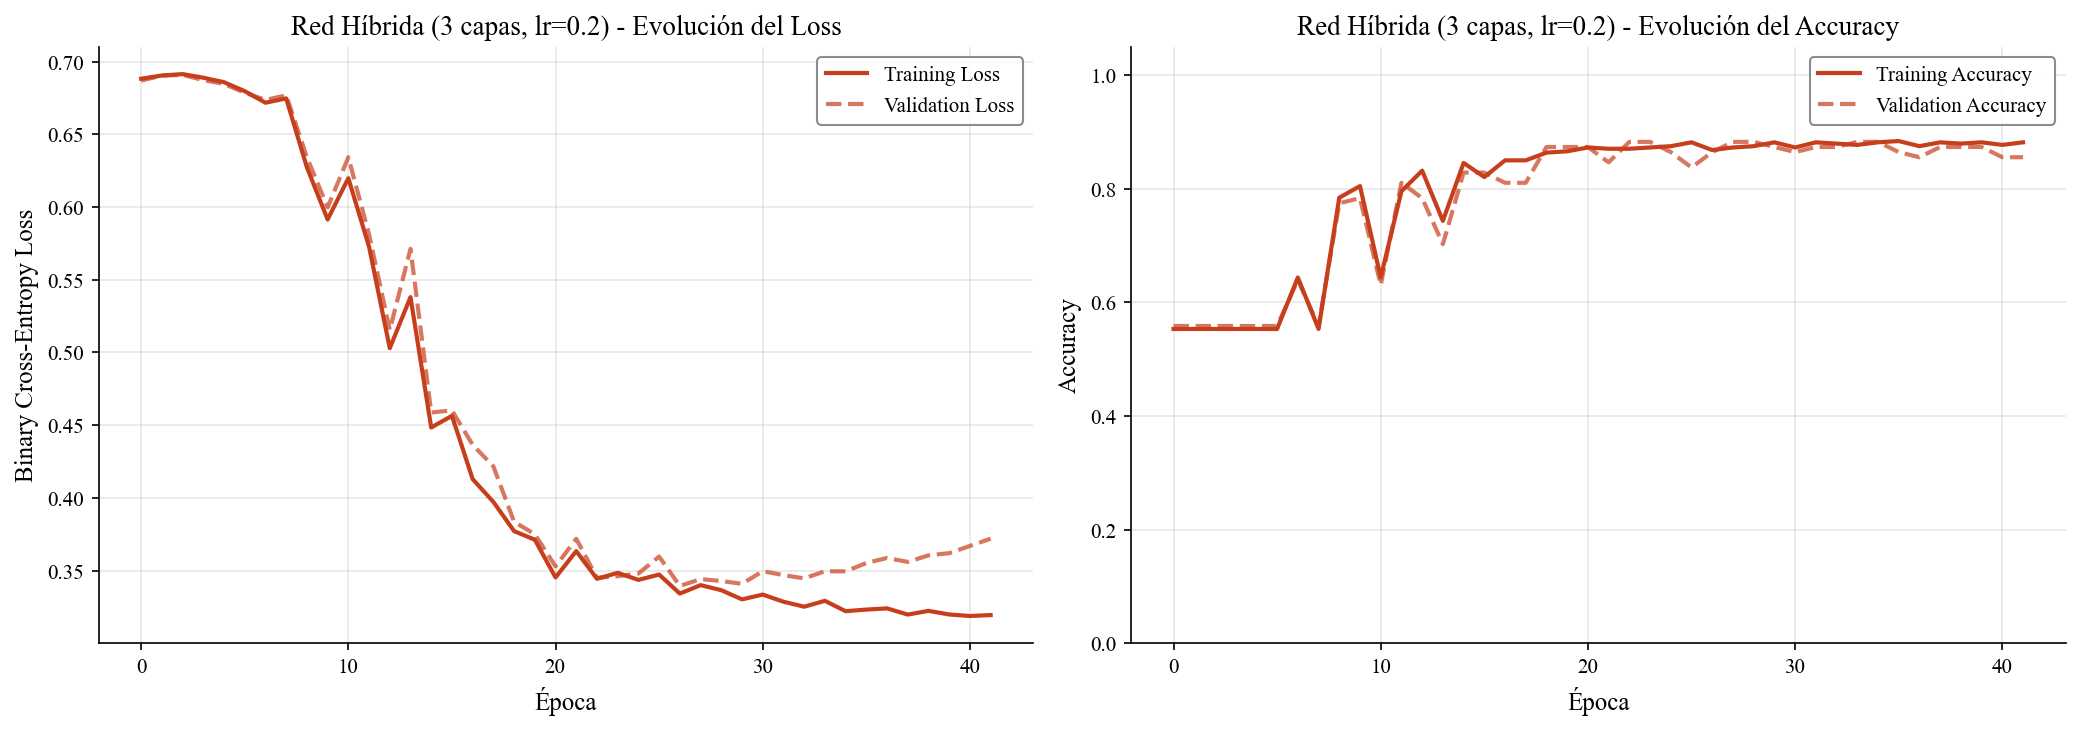

RESULTADOS RED HÍBRIDA ÓPTIMA (3 capas, lr=0.2)
Accuracy:  0.8333
Precision: 0.7879
Recall:    0.8525
F1-Score:  0.8189

Parámetros totales: 153
Tiempo de entrenamiento: 12.39s


In [30]:
# =============================================================================
# GRÁFICAS Y EVALUACIÓN RED HÍBRIDA (1 CAPA)
# =============================================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss
axes[0].plot(history_hybrid_best.tr_losses, label='Training Loss', color=COLORS['hybrid_1'], linewidth=2)
axes[0].plot(history_hybrid_best.val_losses, label='Validation Loss', color=COLORS['hybrid_1'], 
             linestyle='--', linewidth=2, alpha=0.7)
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Binary Cross-Entropy Loss')
axes[0].set_title(f'Red Híbrida ({n_layers_hybrid_best} capas, lr={lr_hybrid_best}) - Evolución del Loss')
axes[0].legend()

# Accuracy
axes[1].plot(history_hybrid_best.tr_accuracy, label='Training Accuracy', color=COLORS['hybrid_1'], linewidth=2)
axes[1].plot(history_hybrid_best.val_accuracy, label='Validation Accuracy', color=COLORS['hybrid_1'], 
             linestyle='--', linewidth=2, alpha=0.7)
axes[1].set_xlabel('Época')
axes[1].set_ylabel('Accuracy')
axes[1].set_title(f'Red Híbrida ({n_layers_hybrid_best} capas, lr={lr_hybrid_best}) - Evolución del Accuracy')
axes[1].legend()
axes[1].set_ylim(0, 1.05)

plt.tight_layout()
plt.savefig('hybrid1_training.png', dpi=300, bbox_inches='tight')
plt.show()

# Evaluación
with torch.no_grad():
    y_proba_hybrid_best = model_hybrid_best(test_data.x).numpy().flatten()
    y_pred_hybrid_best = (y_proba_hybrid_best >= 0.5).astype(int)

hybrid_best_accuracy = accuracy_score(y_test, y_pred_hybrid_best)
hybrid_best_precision = precision_score(y_test, y_pred_hybrid_best)
hybrid_best_recall = recall_score(y_test, y_pred_hybrid_best)
hybrid_best_f1 = f1_score(y_test, y_pred_hybrid_best)

# Contar parámetros totales
n_params_hybrid_best = sum(p.numel() for p in model_hybrid_best.parameters())

print("="*60)
print(f"RESULTADOS RED HÍBRIDA ÓPTIMA ({n_layers_hybrid_best} capas, lr={lr_hybrid_best})")
print("="*60)
print(f"Accuracy:  {hybrid_best_accuracy:.4f}")
print(f"Precision: {hybrid_best_precision:.4f}")
print(f"Recall:    {hybrid_best_recall:.4f}")
print(f"F1-Score:  {hybrid_best_f1:.4f}")
print(f"\nParámetros totales: {n_params_hybrid_best}")
print(f"Tiempo de entrenamiento: {hybrid_best_train_time:.2f}s")

# Guardamos resultados
results['Híbrido (óptimo)'] = {
    'accuracy': hybrid_best_accuracy,
    'precision': hybrid_best_precision,
    'recall': hybrid_best_recall,
    'f1': hybrid_best_f1,
    'time': hybrid_best_train_time,
    'params': n_params_hybrid_best,
    'y_pred': y_pred_hybrid_best,
    'y_proba': y_proba_hybrid_best
}


### 2.C.1) Estudio de Ablación: Red Neuronal Clásica Equivalente

Para determinar si la mejora de rendimiento de la red híbrida proviene de la capa cuántica o de las capas clásicas, creamos una **red neuronal puramente clásica** con arquitectura equivalente.

**Arquitectura equivalente:**
```
Input(4) → Linear(4,4) → ReLU → Linear(4,4) → Linear(4,1) → Sigmoid
```

La capa cuántica (que tiene 4 qubits y retorna 4 valores) se sustituye por una capa densa `Linear(4,4)` con el mismo número de salidas.

**Hipótesis:**
- Si la red clásica equivalente tiene un rendimiento similar al híbrido → el rendimiento no proviene de la capa cuántica
- Si la red híbrida supera significativamente a la clásica equivalente → hay evidencia de "ventaja cuántica"


In [31]:
# =============================================================================
# ESTUDIO DE ABLACIÓN: RED NEURONAL CLÁSICA EQUIVALENTE
# =============================================================================

# Reiniciamos semilla para reproducibilidad
set_seed(rs)

# Usamos los mismos hiperparámetros óptimos del modelo híbrido
lr_classical_nn = lr_hybrid_best

print("="*60)
print("RED NEURONAL CLÁSICA EQUIVALENTE (Ablation Study)")
print("="*60)
print(f"Learning rate: {lr_classical_nn} (mismo que híbrido óptimo)")
print("-"*60)

# Arquitectura equivalente: sustituimos la capa cuántica por Linear(4,4)
# Híbrido: Input → Linear(4,4) → ReLU → QuantumLayer(4→4) → Linear(4,1) → Sigmoid
# Clásico: Input → Linear(4,4) → ReLU → Linear(4,4) → ReLU → Linear(4,1) → Sigmoid
model_classical_nn = nn.Sequential(
    nn.Linear(n_qubits, n_qubits),
    nn.ReLU(),
    nn.Linear(n_qubits, n_qubits),  # Sustituye la capa cuántica
    nn.ReLU(),
    nn.Linear(n_qubits, 1),
    nn.Sigmoid()
)

opt_classical_nn = torch.optim.Adam(model_classical_nn.parameters(), lr=lr_classical_nn)

# Contar parámetros
n_params_classical_nn = sum(p.numel() for p in model_classical_nn.parameters())

print(f"\nArquitectura:")
print(f"  Input(4) → Linear(4,4) → ReLU → Linear(4,4) → ReLU → Linear(4,1) → Sigmoid")
print(f"\nParámetros totales: {n_params_classical_nn}")
print(f"  (Híbrido óptimo tiene {n_params_hybrid_best} parámetros)")
summary(model_classical_nn)


RED NEURONAL CLÁSICA EQUIVALENTE (Ablation Study)
Learning rate: 0.2 (mismo que híbrido óptimo)
------------------------------------------------------------

Arquitectura:
  Input(4) → Linear(4,4) → ReLU → Linear(4,4) → ReLU → Linear(4,1) → Sigmoid

Parámetros totales: 153
  (Híbrido óptimo tiene 153 parámetros)


Layer (type:depth-idx)                   Param #
Sequential                               --
├─Linear: 1-1                            72
├─ReLU: 1-2                              --
├─Linear: 1-3                            72
├─ReLU: 1-4                              --
├─Linear: 1-5                            9
├─Sigmoid: 1-6                           --
Total params: 153
Trainable params: 153
Non-trainable params: 0

Entrenando Red Neuronal Clásica Equivalente...
Epoch 1 | Train loss: 0.9811 | Valid loss: 0.9813
Epoch 2 | Train loss: 1.0027 | Valid loss: 1.0143
Epoch 3 | Train loss: 0.7414 | Valid loss: 0.7463
Epoch 4 | Train loss: 0.6872 | Valid loss: 0.688
Epoch 5 | Train loss: 0.6752 | Valid loss: 0.6761
Epoch 6 | Train loss: 0.6171 | Valid loss: 0.6129
Epoch 7 | Train loss: 0.6498 | Valid loss: 0.6382
Epoch 8 | Train loss: 0.6147 | Valid loss: 0.6223
Epoch 9 | Train loss: 0.5967 | Valid loss: 0.6031
Epoch 10 | Train loss: 0.5533 | Valid loss: 0.5357
Epoch 11 | Train loss: 0.5271 | Valid loss: 0.508
Epoch 12 | Train loss: 0.4978 | Valid loss: 0.5024
Epoch 13 | Train loss: 0.4528 | Valid loss: 0.4559
Epoch 14 | Train loss: 0.4502 | Valid loss: 0.4282
Epoch 15 | Train loss: 0.4345 | Valid loss: 0.4208
Epoch 16 | Train loss: 0.4072 | Valid loss: 0.4253
Epoch 17 | Train loss: 0.378 | Valid loss: 0.3911
Epoch 18 | Train loss: 0.3786 | Valid loss: 0.3932
Epoch 19 | Train loss: 0.3726 | Valid loss: 0.3

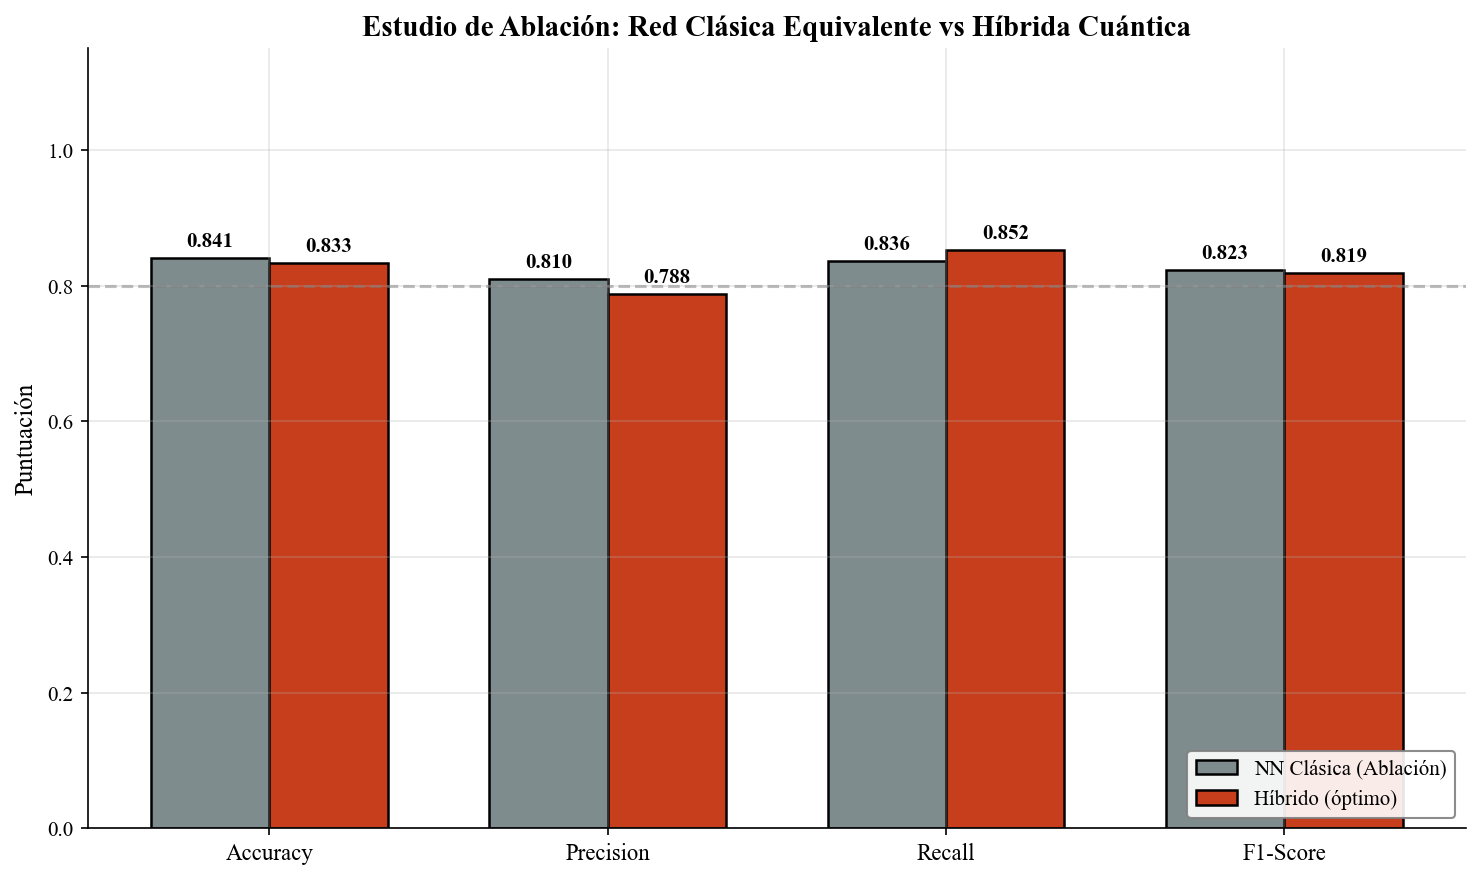


→ La gráfica muestra la comparación directa de las 4 métricas principales


In [32]:
# =============================================================================
# ENTRENAMIENTO Y EVALUACIÓN RED CLÁSICA EQUIVALENTE
# =============================================================================

print("Entrenando Red Neuronal Clásica Equivalente...")
print("="*60)

start_time = time.time()
history_classical_nn = train(
    model=model_classical_nn, 
    loss=loss_fn, 
    opt=opt_classical_nn, 
    tr_data=tr_data, 
    val_data=val_data, 
    max_epochs=150, 
    patience=15
)
classical_nn_train_time = time.time() - start_time

print(f"\nTiempo total de entrenamiento: {classical_nn_train_time:.2f} segundos")

# Evaluación
with torch.no_grad():
    y_proba_classical_nn = model_classical_nn(test_data.x).numpy().flatten()
    y_pred_classical_nn = (y_proba_classical_nn >= 0.5).astype(int)

classical_nn_accuracy = accuracy_score(y_test, y_pred_classical_nn)
classical_nn_precision = precision_score(y_test, y_pred_classical_nn)
classical_nn_recall = recall_score(y_test, y_pred_classical_nn)
classical_nn_f1 = f1_score(y_test, y_pred_classical_nn)

print("\n" + "="*60)
print("RESULTADOS RED CLÁSICA EQUIVALENTE (Ablation)")
print("="*60)
print(f"Accuracy:  {classical_nn_accuracy:.4f}")
print(f"Precision: {classical_nn_precision:.4f}")
print(f"Recall:    {classical_nn_recall:.4f}")
print(f"F1-Score:  {classical_nn_f1:.4f}")
print(f"\nParámetros totales: {n_params_classical_nn}")
print(f"Tiempo de entrenamiento: {classical_nn_train_time:.2f}s")

# Guardamos resultados
results['NN Clásica (Ablation)'] = {
    'accuracy': classical_nn_accuracy,
    'precision': classical_nn_precision,
    'recall': classical_nn_recall,
    'f1': classical_nn_f1,
    'time': classical_nn_train_time,
    'params': n_params_classical_nn,
    'y_pred': y_pred_classical_nn,
    'y_proba': y_proba_classical_nn
}

# Comparación con el híbrido
print("\n" + "="*60)
print("COMPARACIÓN: HÍBRIDO vs CLÁSICO EQUIVALENTE")
print("="*60)
diff_f1 = hybrid_best_f1 - classical_nn_f1
diff_acc = hybrid_best_accuracy - classical_nn_accuracy
print(f"\nHíbrido óptimo:      F1={hybrid_best_f1:.4f}, Acc={hybrid_best_accuracy:.4f}")
print(f"Clásico equivalente: F1={classical_nn_f1:.4f}, Acc={classical_nn_accuracy:.4f}")
print(f"\nDiferencia (Híbrido - Clásico):")
print(f"  - F1-Score: {diff_f1:+.4f} ({100*diff_f1/classical_nn_f1:+.2f}%)")
print(f"  - Accuracy: {diff_acc:+.4f} ({100*diff_acc/classical_nn_accuracy:+.2f}%)")

if diff_f1 > 0.02:
    print("\n✓ Evidencia de VENTAJA CUÁNTICA: La capa cuántica aporta rendimiento adicional")
elif diff_f1 > -0.02:
    print("\n≈ Rendimiento SIMILAR: No hay evidencia clara de ventaja cuántica")
else:
    print("\n✗ La red clásica equivalente supera al híbrido")

# =============================================================================
# GRÁFICA DE BENCHMARK: ESTUDIO DE ABLACIÓN
# =============================================================================

# Preparar datos para la gráfica
models_ablation = ['NN Clásica\n(Ablación)', 'Híbrido\n(óptimo)']
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score']

classical_metrics = [classical_nn_accuracy, classical_nn_precision, classical_nn_recall, classical_nn_f1]
hybrid_metrics = [hybrid_best_accuracy, hybrid_best_precision, hybrid_best_recall, hybrid_best_f1]

x = np.arange(len(metrics_names))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

# Barras agrupadas
bars1 = ax.bar(x - width/2, classical_metrics, width, label='NN Clásica (Ablación)', 
               color='#7f8c8d', edgecolor='black', linewidth=1.2)
bars2 = ax.bar(x + width/2, hybrid_metrics, width, label='Híbrido (óptimo)', 
               color=COLORS['hybrid_1'], edgecolor='black', linewidth=1.2)

# Etiquetas de valor sobre las barras
def add_labels(bars):
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.3f}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=10, fontweight='bold')

add_labels(bars1)
add_labels(bars2)

# Configuración del gráfico
ax.set_ylabel('Puntuación', fontsize=12)
ax.set_title('Estudio de Ablación: Red Clásica Equivalente vs Híbrida Cuántica', 
             fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(metrics_names, fontsize=11)
ax.legend(loc='lower right', fontsize=10)
ax.set_ylim(0, 1.15)
ax.grid(axis='y', alpha=0.3)

# Línea de referencia
ax.axhline(y=0.8, color='gray', linestyle='--', alpha=0.5, label='Ref: 80%')

plt.tight_layout()
plt.savefig('ablation_benchmark.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n→ La gráfica muestra la comparación directa de las 4 métricas principales")


---

<a name="2d-baseline"></a>
## 2.D) Baseline Clásico (SVM con Kernel RBF + GridSearchCV)

Para evaluar objetivamente los modelos cuánticos, comparamos con un **clasificador clásico estado del arte**: SVM con kernel RBF (Radial Basis Function), **optimizado mediante GridSearchCV**.

$$K(\mathbf{x}_1, \mathbf{x}_2) = \exp\left(-\gamma \|\mathbf{x}_1 - \mathbf{x}_2\|^2\right)$$

Este kernel es conocido por su excelente rendimiento en problemas de clasificación no lineal.

**Importante:** Para una comparación justa con los modelos cuánticos (que también fueron optimizados via búsqueda de hiperparámetros), aplicamos GridSearchCV para encontrar los mejores valores de:
- **C**: Parámetro de regularización
- **gamma**: Coeficiente del kernel RBF


In [33]:
# =============================================================================
# BASELINE CLÁSICO: SVM CON KERNEL RBF + GRIDSEARCHCV
# =============================================================================

# Definimos el grid de hiperparámetros para una comparación justa
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 0.1, 0.01]
}

print("="*60)
print("BÚSQUEDA DE HIPERPARÁMETROS SVM CLÁSICO (GridSearchCV)")
print("="*60)
print(f"Parámetros a optimizar:")
print(f"  - C: {param_grid['C']}")
print(f"  - gamma: {param_grid['gamma']}")
print(f"  - Total combinaciones: {len(param_grid['C']) * len(param_grid['gamma'])}")
print("-"*60)

# GridSearchCV con validación cruzada 5-fold
start_time = time.time()
svm_base = SVC(kernel='rbf', random_state=rs, probability=True)
grid_search = GridSearchCV(
    svm_base, 
    param_grid, 
    cv=5, 
    scoring='f1',
    n_jobs=-1,
    verbose=1
)
grid_search.fit(X_train_final, y_train)
classical_train_time = time.time() - start_time

# Mejor modelo encontrado
svm_classical = grid_search.best_estimator_
best_params = grid_search.best_params_

print(f"\n✓ MEJORES HIPERPARÁMETROS ENCONTRADOS:")
print(f"  - C: {best_params['C']}")
print(f"  - gamma: {best_params['gamma']}")
print(f"  - Mejor F1 (CV): {grid_search.best_score_:.4f}")

# Predicciones con el mejor modelo
y_pred_classical = svm_classical.predict(X_test_final)
y_proba_classical = svm_classical.predict_proba(X_test_final)[:, 1]

# Métricas en test
classical_accuracy = accuracy_score(y_test, y_pred_classical)
classical_precision = precision_score(y_test, y_pred_classical)
classical_recall = recall_score(y_test, y_pred_classical)
classical_f1 = f1_score(y_test, y_pred_classical)

print("\n" + "="*60)
print("RESULTADOS BASELINE CLÁSICO OPTIMIZADO (SVM RBF)")
print("="*60)
print(f"Accuracy:  {classical_accuracy:.4f}")
print(f"Precision: {classical_precision:.4f}")
print(f"Recall:    {classical_recall:.4f}")
print(f"F1-Score:  {classical_f1:.4f}")
print(f"\nTiempo total (búsqueda + entrenamiento): {classical_train_time:.4f}s")

# Guardamos resultados
results['SVM Clásico (RBF)'] = {
    'accuracy': classical_accuracy,
    'precision': classical_precision,
    'recall': classical_recall,
    'f1': classical_f1,
    'time': classical_train_time,
    'params': f"C={best_params['C']}, γ={best_params['gamma']}",
    'y_pred': y_pred_classical,
    'y_proba': y_proba_classical,
    'best_params': best_params
}


BÚSQUEDA DE HIPERPARÁMETROS SVM CLÁSICO (GridSearchCV)
Parámetros a optimizar:
  - C: [0.1, 1, 10, 100]
  - gamma: ['scale', 0.1, 0.01]
  - Total combinaciones: 12
------------------------------------------------------------
Fitting 5 folds for each of 12 candidates, totalling 60 fits

✓ MEJORES HIPERPARÁMETROS ENCONTRADOS:
  - C: 1
  - gamma: 0.01
  - Mejor F1 (CV): 0.8630

RESULTADOS BASELINE CLÁSICO OPTIMIZADO (SVM RBF)
Accuracy:  0.8043
Precision: 0.7125
Recall:    0.9344
F1-Score:  0.8085

Tiempo total (búsqueda + entrenamiento): 4.7042s


---

<a name="3-análisis"></a>
## 3. Análisis Comparativo y Conclusiones

### 3.1 Tabla Comparativa de Resultados


In [34]:
# =============================================================================
# TABLA COMPARATIVA DE RESULTADOS
# =============================================================================

# Creamos DataFrame con los resultados
results_df = pd.DataFrame({
    'Modelo': list(results.keys()),
    'Accuracy': [r['accuracy'] for r in results.values()],
    'Precision': [r['precision'] for r in results.values()],
    'Recall': [r['recall'] for r in results.values()],
    'F1-Score': [r['f1'] for r in results.values()],
    'Tiempo (s)': [r['time'] for r in results.values()],
    'Parámetros': [r['params'] for r in results.values()]
})

# Ordenamos por F1-Score descendente
results_df = results_df.sort_values('F1-Score', ascending=False).reset_index(drop=True)

# Mostramos la tabla
print("="*80)
print("TABLA COMPARATIVA DE MODELOS")
print("="*80)
print(results_df.to_string(index=False))

# Guardamos como CSV
results_df.to_csv('results_comparison.csv', index=False)
print("\nTabla guardada en 'results_comparison.csv'")


TABLA COMPARATIVA DE MODELOS
               Modelo  Accuracy  Precision   Recall  F1-Score  Tiempo (s)  Parámetros
NN Clásica (Ablation)  0.840580   0.809524 0.836066  0.822581    0.240468         153
     Híbrido (óptimo)  0.833333   0.787879 0.852459  0.818898   12.394695         153
    SVM Clásico (RBF)  0.804348   0.712500 0.934426  0.808511    4.704199 C=1, γ=0.01
         QNN (óptimo)  0.811594   0.753623 0.852459  0.800000    6.999317          48
                 QSVM  0.782609   0.701299 0.885246  0.782609  462.624777         N/A

Tabla guardada en 'results_comparison.csv'


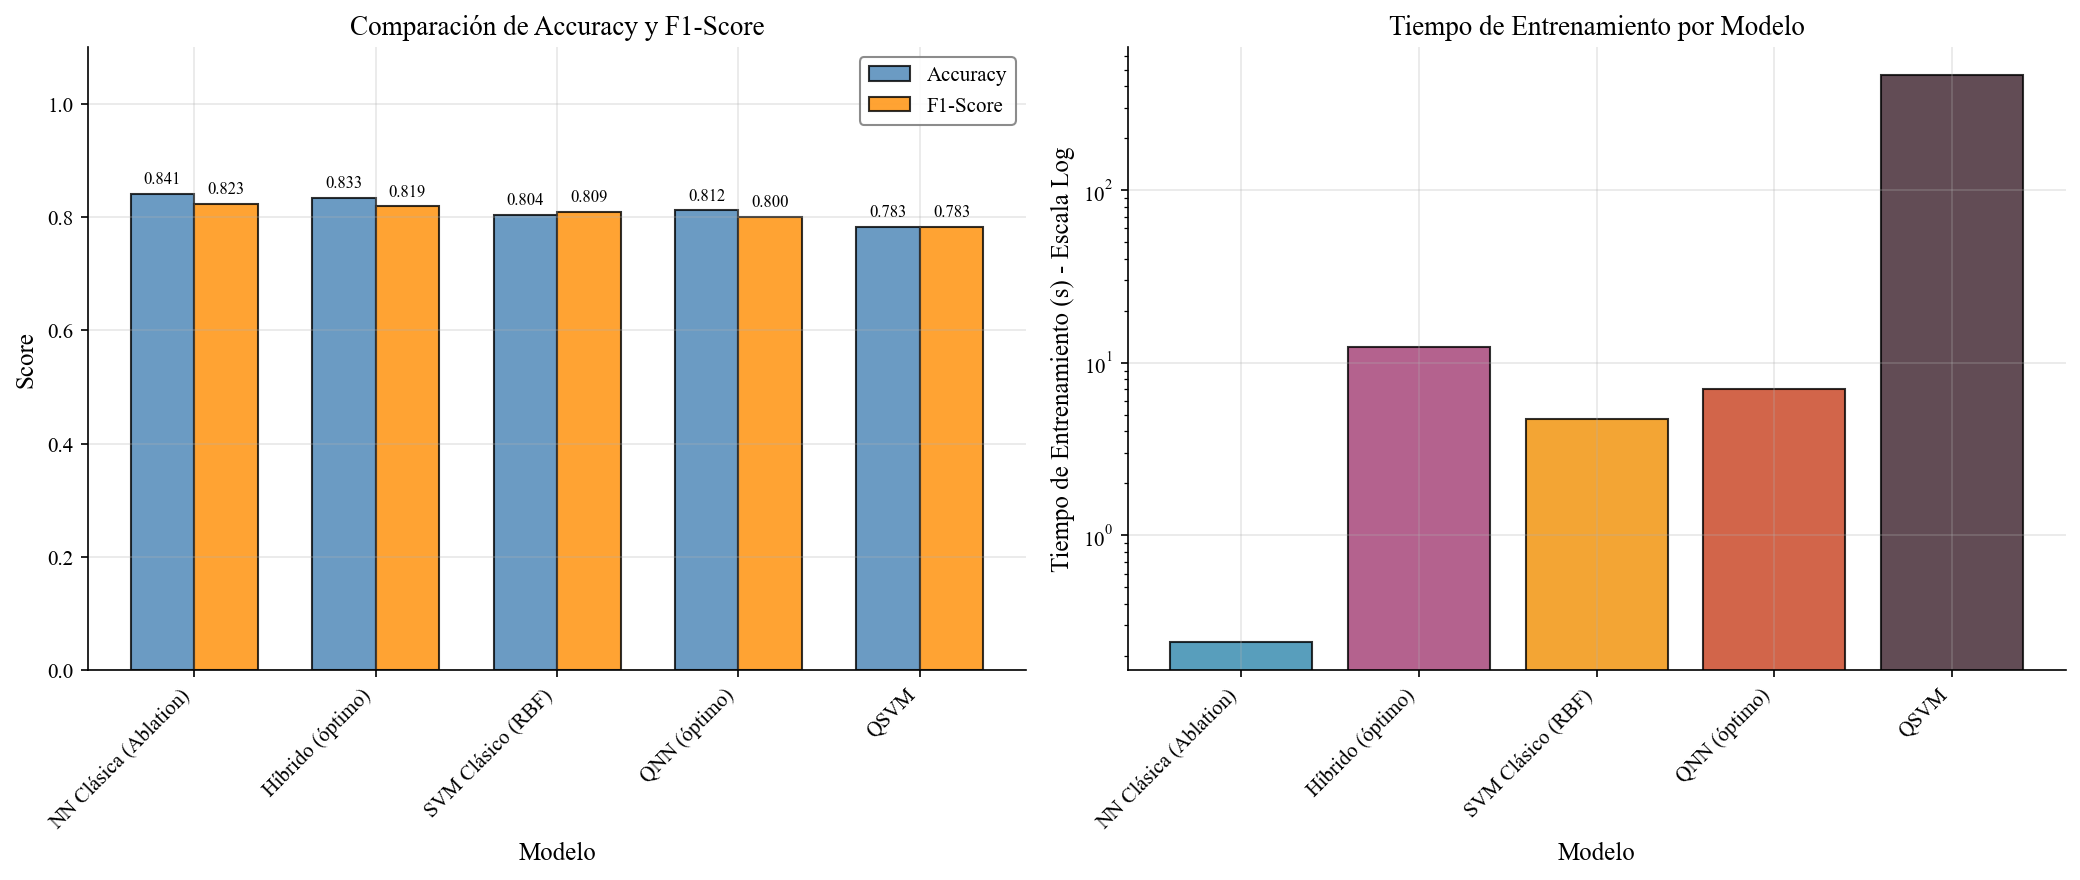

In [35]:
# =============================================================================
# GRÁFICO COMPARATIVO DE MÉTRICAS
# =============================================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Colores para cada modelo
model_colors = [COLORS['qsvm'], COLORS['qnn_1'], COLORS['qnn_2'], 
                COLORS['hybrid_1'], COLORS['hybrid_2'], COLORS['classical']]

# Gráfico de barras: Accuracy y F1-Score
metrics = ['Accuracy', 'F1-Score']
x = np.arange(len(results_df))
width = 0.35

bars1 = axes[0].bar(x - width/2, results_df['Accuracy'], width, label='Accuracy', 
                     color='steelblue', edgecolor='black', alpha=0.8)
bars2 = axes[0].bar(x + width/2, results_df['F1-Score'], width, label='F1-Score', 
                     color='darkorange', edgecolor='black', alpha=0.8)

axes[0].set_xlabel('Modelo')
axes[0].set_ylabel('Score')
axes[0].set_title('Comparación de Accuracy y F1-Score')
axes[0].set_xticks(x)
axes[0].set_xticklabels(results_df['Modelo'], rotation=45, ha='right')
axes[0].legend()
axes[0].set_ylim(0, 1.1)

# Añadir valores sobre las barras
for bar in bars1:
    height = bar.get_height()
    axes[0].annotate(f'{height:.3f}', xy=(bar.get_x() + bar.get_width()/2, height),
                     xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8)
for bar in bars2:
    height = bar.get_height()
    axes[0].annotate(f'{height:.3f}', xy=(bar.get_x() + bar.get_width()/2, height),
                     xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8)

# Gráfico de tiempo de entrenamiento (escala logarítmica)
bars3 = axes[1].bar(results_df['Modelo'], results_df['Tiempo (s)'], 
                     color=model_colors[:len(results_df)], edgecolor='black', alpha=0.8)
axes[1].set_xlabel('Modelo')
axes[1].set_ylabel('Tiempo de Entrenamiento (s) - Escala Log')
axes[1].set_title('Tiempo de Entrenamiento por Modelo')
axes[1].set_yscale('log')
axes[1].set_xticklabels(results_df['Modelo'], rotation=45, ha='right')

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=300, bbox_inches='tight')
plt.show()


### 3.2 Matrices de Confusión

Las matrices de confusión muestran el desglose de predicciones correctas e incorrectas para cada modelo.


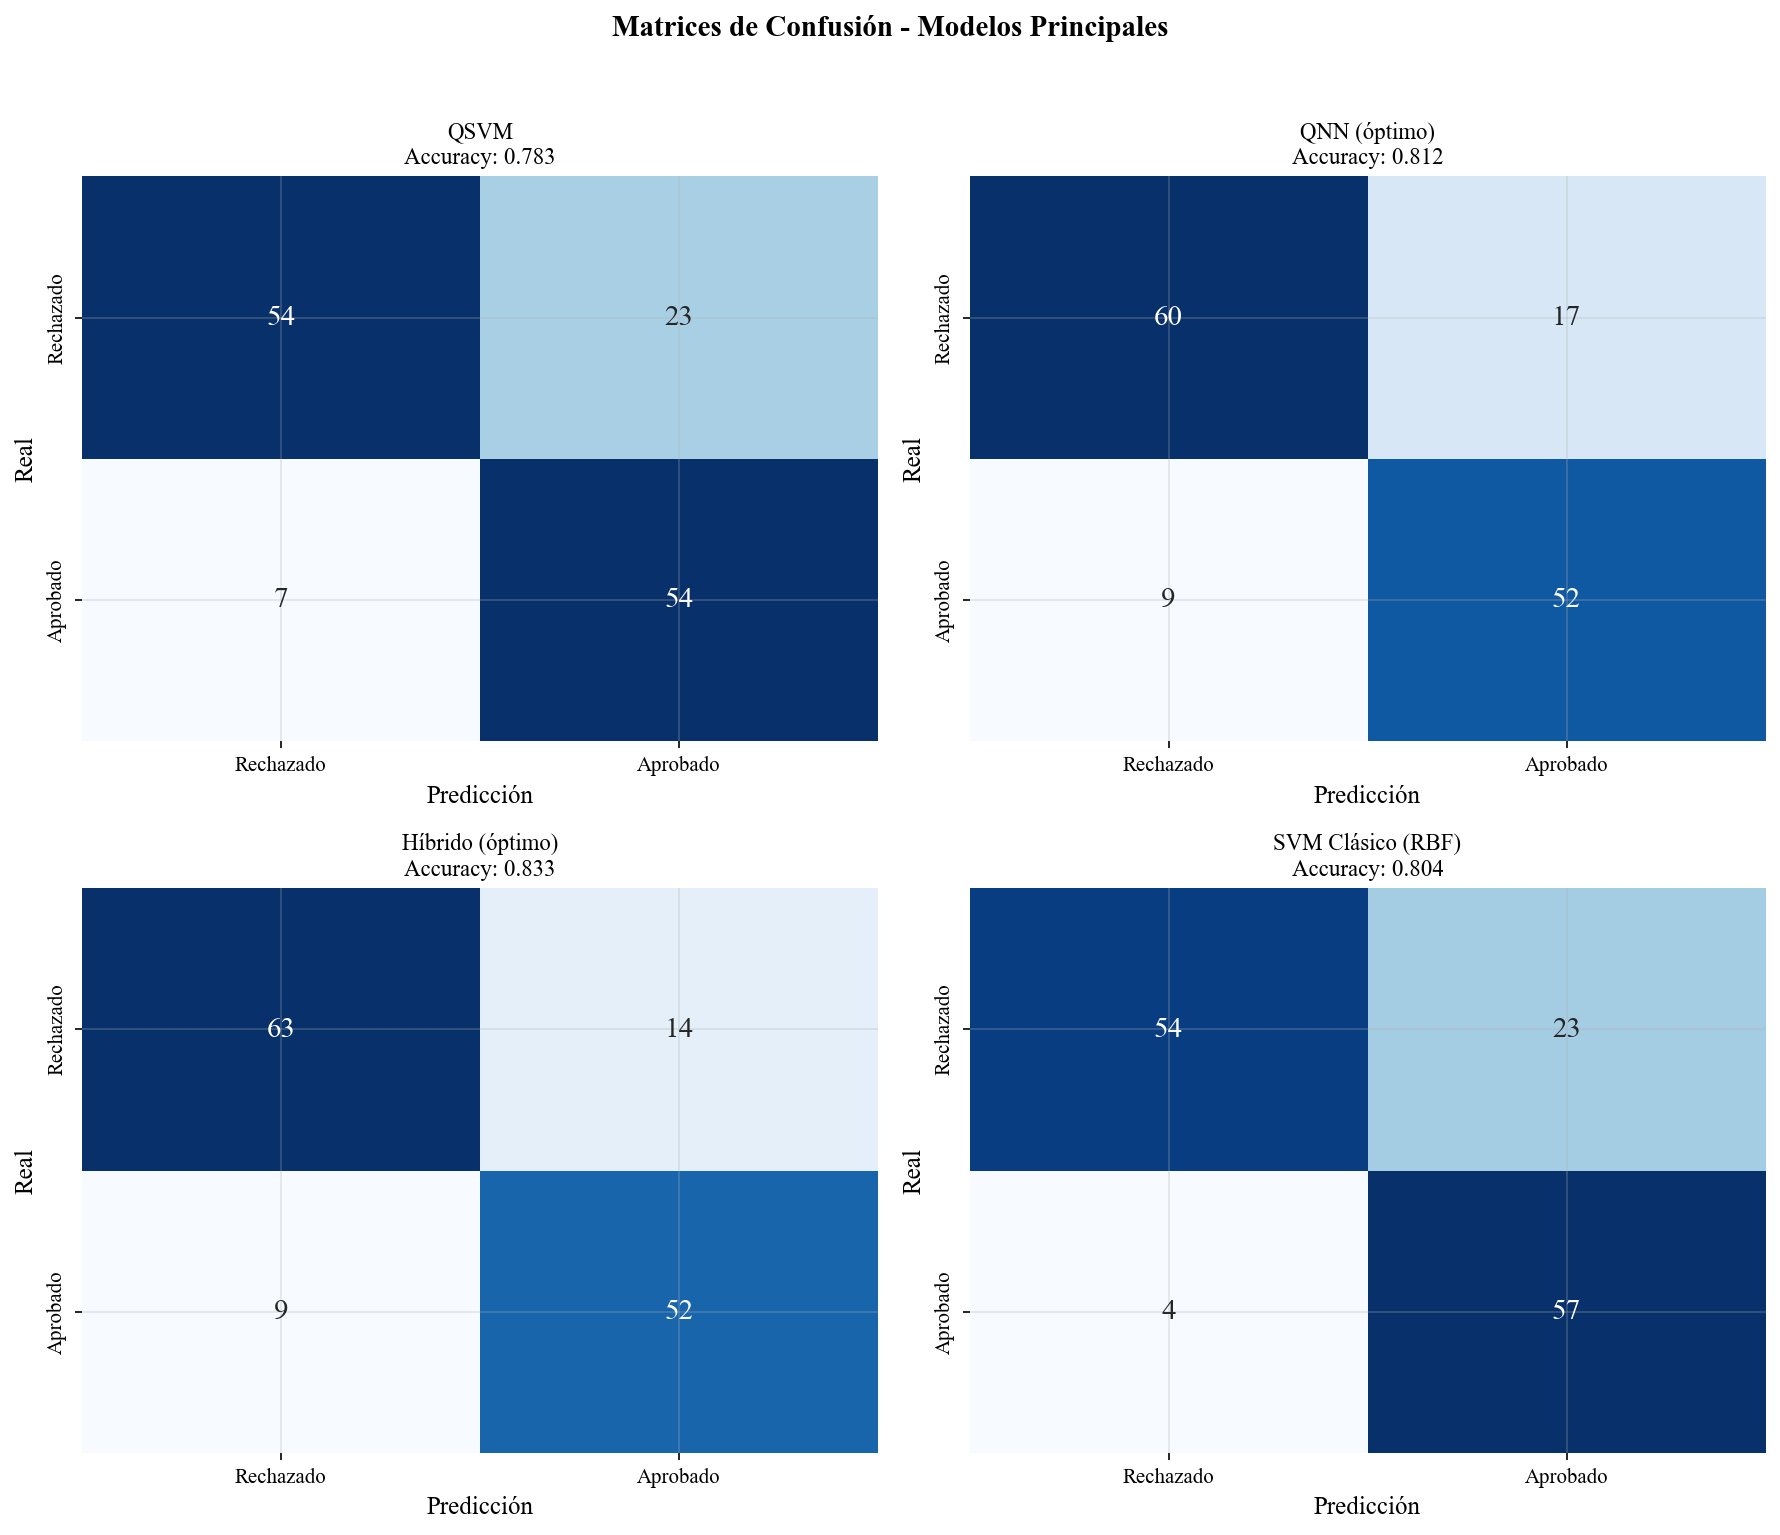

In [36]:
# =============================================================================
# MATRICES DE CONFUSIÓN
# =============================================================================

# Solo mostramos los modelos más importantes para mantener la visualización clara
key_models = ['QSVM', 'QNN (óptimo)', 'Híbrido (óptimo)', 'SVM Clásico (RBF)']

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for idx, model_name in enumerate(key_models):
    if model_name in results:
        model_results = results[model_name]
        cm = confusion_matrix(y_test, model_results['y_pred'])
        
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                    xticklabels=['Rechazado', 'Aprobado'],
                    yticklabels=['Rechazado', 'Aprobado'],
                    cbar=False, annot_kws={"size": 14})
        
        axes[idx].set_title(f'{model_name}\nAccuracy: {model_results["accuracy"]:.3f}', fontsize=11)
        axes[idx].set_xlabel('Predicción')
        axes[idx].set_ylabel('Real')

plt.suptitle('Matrices de Confusión - Modelos Principales', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()


### 3.3 Curvas ROC y AUC

La curva ROC (Receiver Operating Characteristic) muestra el trade-off entre sensibilidad (TPR) y especificidad (1-FPR). El área bajo la curva (AUC) proporciona una medida única de rendimiento.


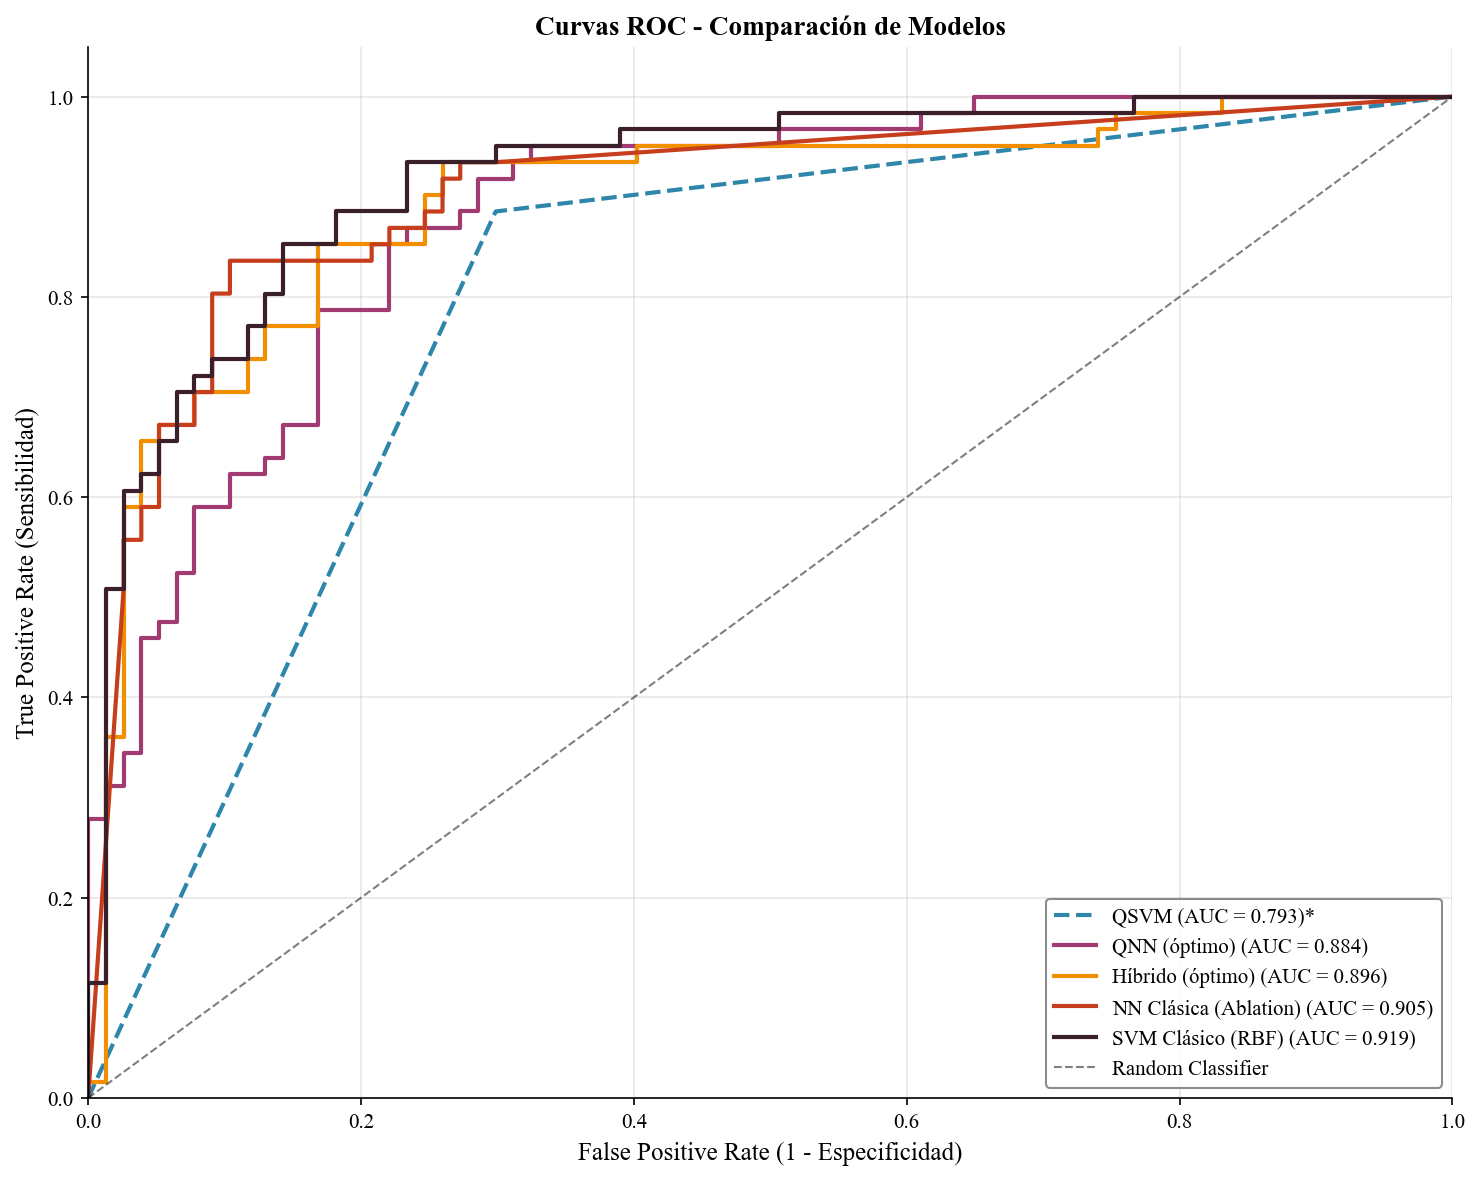

* Los modelos marcados con asterisco no proporcionan probabilidades, se usa predicción directa.


In [37]:
# =============================================================================
# CURVAS ROC
# =============================================================================

plt.figure(figsize=(10, 8))

# Colores para las curvas
colors_list = list(COLORS.values())

for idx, (model_name, model_results) in enumerate(results.items()):
    if model_results['y_proba'] is not None:
        fpr, tpr, _ = roc_curve(y_test, model_results['y_proba'])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, color=colors_list[idx % len(colors_list)], linewidth=2,
                 label=f'{model_name} (AUC = {roc_auc:.3f})')
    else:
        # Para modelos sin probabilidades (QSVM), usamos predicción directa
        fpr, tpr, _ = roc_curve(y_test, model_results['y_pred'])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, color=colors_list[idx % len(colors_list)], linewidth=2,
                 linestyle='--', label=f'{model_name} (AUC = {roc_auc:.3f})*')

# Línea diagonal (clasificador aleatorio)
plt.plot([0, 1], [0, 1], 'k--', linewidth=1, alpha=0.5, label='Random Classifier')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Especificidad)')
plt.ylabel('True Positive Rate (Sensibilidad)')
plt.title('Curvas ROC - Comparación de Modelos', fontweight='bold')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('roc_curves.png', dpi=300, bbox_inches='tight')
plt.show()

print("* Los modelos marcados con asterisco no proporcionan probabilidades, se usa predicción directa.")


### 3.4 Análisis de Sensibilidad: Efecto del Número de Capas


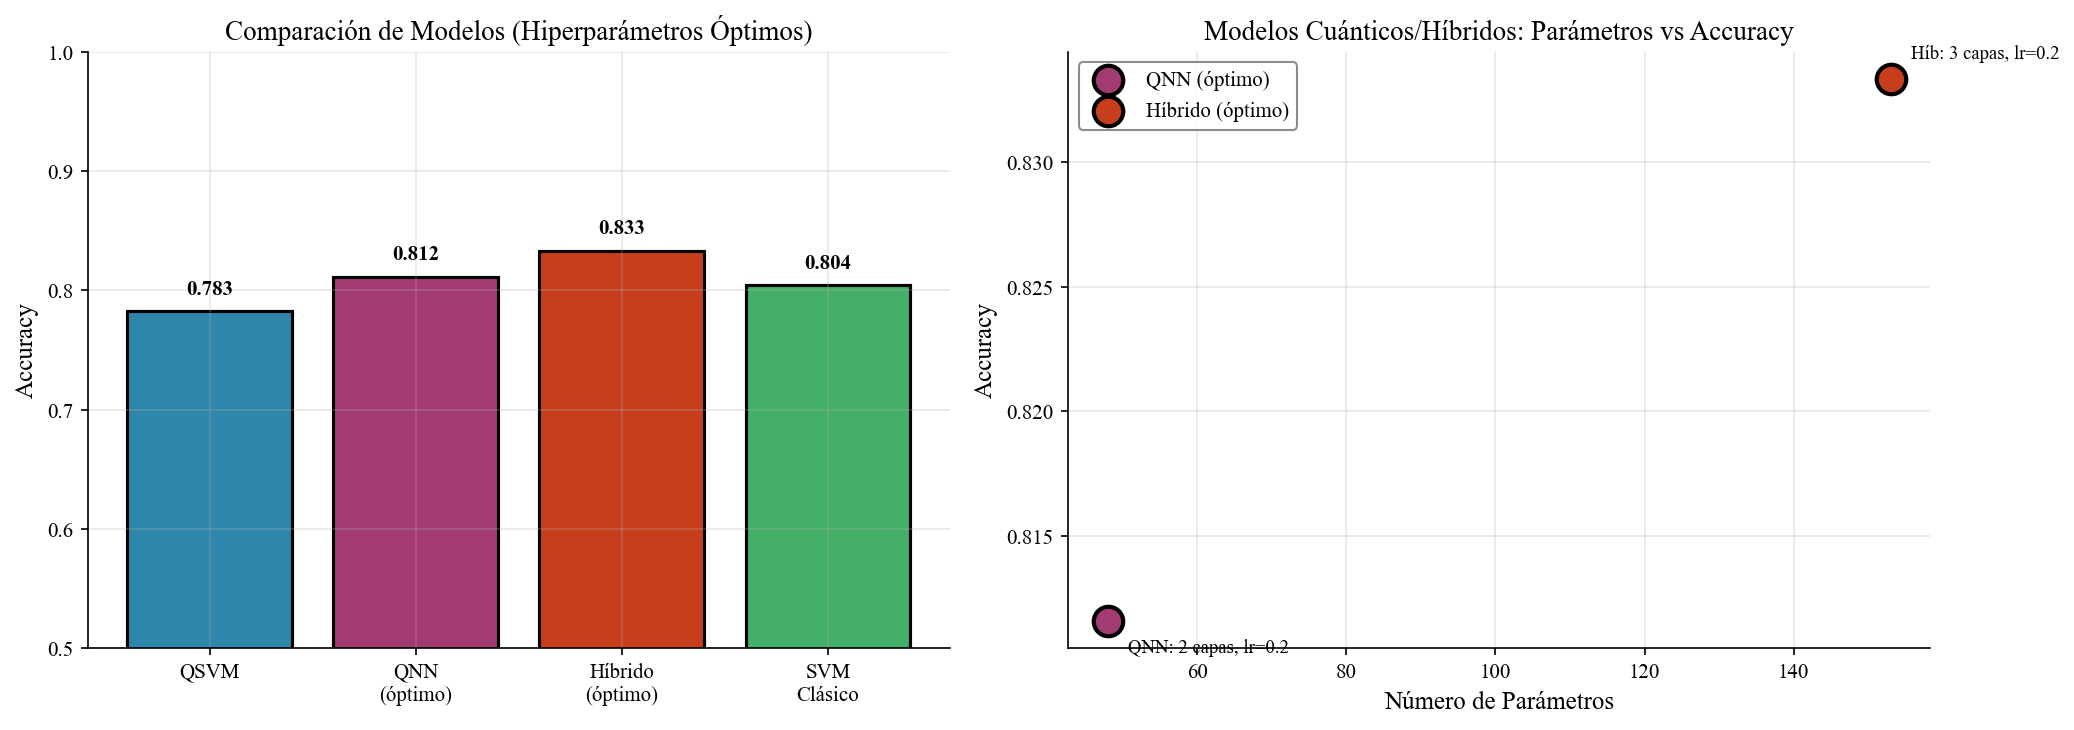


RESUMEN DE HIPERPARÁMETROS ÓPTIMOS

QNN óptimo:
  - Capas: 2
  - Learning rate: 0.2
  - Parámetros: 48
  - Accuracy: 0.8116

Híbrido óptimo:
  - Capas: 3
  - Learning rate: 0.2
  - Parámetros: 153
  - Accuracy: 0.8333


In [38]:
# =============================================================================
# ANÁLISIS DE SENSIBILIDAD: RESULTADOS DE BÚSQUEDA DE HIPERPARÁMETROS
# =============================================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Comparación de modelos (barras)
models = ['QSVM', 'QNN\n(óptimo)', 'Híbrido\n(óptimo)', 'SVM\nClásico']
accuracies = [
    results['QSVM']['accuracy'],
    results['QNN (óptimo)']['accuracy'],
    results['Híbrido (óptimo)']['accuracy'],
    results['SVM Clásico (RBF)']['accuracy']
]
colors_bars = [COLORS['qsvm'], COLORS['qnn_1'], COLORS['hybrid_1'], COLORS['classical']]

bars = axes[0].bar(models, accuracies, color=colors_bars, edgecolor='black', linewidth=1.5)
axes[0].set_ylabel('Accuracy')
axes[0].set_title('Comparación de Modelos (Hiperparámetros Óptimos)')
axes[0].set_ylim(0.5, 1.0)

# Añadir valores sobre las barras
for bar, acc in zip(bars, accuracies):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
                 f'{acc:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

# Gráfico 2: Parámetros vs Accuracy para modelos cuánticos/híbridos
quantum_models = ['QNN (óptimo)', 'Híbrido (óptimo)']
quantum_params = [
    results['QNN (óptimo)']['params'],
    results['Híbrido (óptimo)']['params']
]
quantum_acc = [
    results['QNN (óptimo)']['accuracy'],
    results['Híbrido (óptimo)']['accuracy']
]
quantum_colors = [COLORS['qnn_1'], COLORS['hybrid_1']]

for p, a, label, c in zip(quantum_params, quantum_acc, quantum_models, quantum_colors):
    axes[1].scatter(p, a, s=200, color=c, edgecolor='black', linewidth=2, zorder=5, label=label)

# Añadir información de hiperparámetros óptimos
axes[1].annotate(f'QNN: {n_layers_qnn_best} capas, lr={lr_qnn_best}', 
                 (quantum_params[0], quantum_acc[0]), 
                 textcoords="offset points", xytext=(10, -15), fontsize=9)
axes[1].annotate(f'Híb: {n_layers_hybrid_best} capas, lr={lr_hybrid_best}', 
                 (quantum_params[1], quantum_acc[1]), 
                 textcoords="offset points", xytext=(10, 10), fontsize=9)

axes[1].set_xlabel('Número de Parámetros')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Modelos Cuánticos/Híbridos: Parámetros vs Accuracy')
axes[1].legend()

plt.tight_layout()
plt.savefig('sensitivity_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

# Imprimir resumen de hiperparámetros óptimos
print("\n" + "="*60)
print("RESUMEN DE HIPERPARÁMETROS ÓPTIMOS")
print("="*60)
print(f"\nQNN óptimo:")
print(f"  - Capas: {n_layers_qnn_best}")
print(f"  - Learning rate: {lr_qnn_best}")
print(f"  - Parámetros: {results['QNN (óptimo)']['params']}")
print(f"  - Accuracy: {results['QNN (óptimo)']['accuracy']:.4f}")

print(f"\nHíbrido óptimo:")
print(f"  - Capas: {n_layers_hybrid_best}")
print(f"  - Learning rate: {lr_hybrid_best}")
print(f"  - Parámetros: {results['Híbrido (óptimo)']['params']}")
print(f"  - Accuracy: {results['Híbrido (óptimo)']['accuracy']:.4f}")


### 3.4.5 Robustez Estadística: Análisis con Múltiples Semillas

Para evaluar la **robustez estadística** de los resultados, ejecutamos los dos mejores modelos con 5 semillas diferentes. Esto permite:
- Cuantificar la **variabilidad** del rendimiento
- Reportar resultados como **Media ± Desviación Estándar**
- Detectar si un modelo es consistentemente mejor que otro

**Modelos evaluados:**
- Híbrido óptimo (mejor modelo cuántico)
- SVM Clásico optimizado (baseline con GridSearchCV)


In [42]:
# =============================================================================
# ROBUSTEZ ESTADÍSTICA: ANÁLISIS CON MÚLTIPLES SEMILLAS
# =============================================================================

# Semillas para evaluar robustez
seeds = [42, 123, 456, 789, 1024, 2024, 3141, 2718, 1337, 9999]
print("="*70)
print("ANÁLISIS DE ROBUSTEZ CON MÚLTIPLES SEMILLAS")
print("="*70)
print(f"Semillas: {seeds}")
print("-"*70)

# Almacenar resultados por modelo y semilla
robustness_results = {
    'Híbrido': {'f1': [], 'accuracy': []},
    'SVM Clásico': {'f1': [], 'accuracy': []}
}

for seed in seeds:
    print(f"\n🌱 Semilla: {seed}")
    
    # ----- HÍBRIDO ÓPTIMO -----
    set_seed(seed)
    
    # Crear modelo híbrido con hiperparámetros óptimos
    weight_shapes_rob = {"weights": (n_layers_hybrid_best, n_qubits, 3)}
    qlayer_rob = qml.qnn.TorchLayer(hybrid_circuit, weight_shapes_rob)
    
    model_rob = nn.Sequential(
        nn.Linear(n_qubits, n_qubits),
        nn.ReLU(),
        qlayer_rob,
        nn.Linear(n_qubits, 1),
        nn.Sigmoid()
    )
    
    opt_rob = torch.optim.Adam(model_rob.parameters(), lr=lr_hybrid_best)
    
    # Entrenar silenciosamente
    for epoch in range(50):
        opt_rob.zero_grad()
        loss = F.binary_cross_entropy(model_rob(tr_data.x), tr_data.y)
        loss.backward()
        opt_rob.step()
    
    # Evaluar
    with torch.no_grad():
        y_pred_rob = (model_rob(test_data.x).numpy() >= 0.5).astype(int).flatten()
    
    f1_hybrid = f1_score(y_test, y_pred_rob)
    acc_hybrid = accuracy_score(y_test, y_pred_rob)
    robustness_results['Híbrido']['f1'].append(f1_hybrid)
    robustness_results['Híbrido']['accuracy'].append(acc_hybrid)
    
    # ----- SVM CLÁSICO (con split diferente) -----
    # Re-dividir datos con nueva semilla
    X_temp_rob, X_test_rob, y_temp_rob, y_test_rob = train_test_split(
        X, y, test_size=0.20, stratify=y, random_state=seed
    )
    X_train_rob, X_val_rob, y_train_rob, y_val_rob = train_test_split(
        X_temp_rob, y_temp_rob, test_size=0.20, stratify=y_temp_rob, random_state=seed
    )
    
    # Preprocesar
    X_train_prep_rob = preprocessor.transform(X_train_rob)
    X_test_prep_rob = preprocessor.transform(X_test_rob)
    
    # PCA + re-escalar
    X_train_pca_rob = pca.transform(X_train_prep_rob)
    X_test_pca_rob = pca.transform(X_test_prep_rob)
    
    X_train_final_rob = scaler_pca.transform(X_train_pca_rob)
    X_test_final_rob = scaler_pca.transform(X_test_pca_rob)
    
    # Entrenar SVM con mejores hiperparámetros
    svm_rob = SVC(
        kernel='rbf', 
        C=best_params.get('C', 1), 
        gamma=best_params.get('gamma', 'scale'),
        random_state=seed
    )
    svm_rob.fit(X_train_final_rob, y_train_rob)
    
    # Evaluar
    y_pred_svm_rob = svm_rob.predict(X_test_final_rob)
    f1_svm = f1_score(y_test_rob, y_pred_svm_rob)
    acc_svm = accuracy_score(y_test_rob, y_pred_svm_rob)
    robustness_results['SVM Clásico']['f1'].append(f1_svm)
    robustness_results['SVM Clásico']['accuracy'].append(acc_svm)
    
    print(f"   Híbrido:     F1={f1_hybrid:.4f}, Acc={acc_hybrid:.4f}")
    print(f"   SVM Clásico: F1={f1_svm:.4f}, Acc={acc_svm:.4f}")

print("\n" + "="*70)


ANÁLISIS DE ROBUSTEZ CON MÚLTIPLES SEMILLAS
Semillas: [42, 123, 456, 789, 1024, 2024, 3141, 2718, 1337, 9999]
----------------------------------------------------------------------

🌱 Semilla: 42
   Híbrido:     F1=0.8000, Acc=0.8116
   SVM Clásico: F1=0.8085, Acc=0.8043

🌱 Semilla: 123
   Híbrido:     F1=0.7586, Acc=0.7971
   SVM Clásico: F1=0.8413, Acc=0.8551

🌱 Semilla: 456
   Híbrido:     F1=0.8000, Acc=0.8043
   SVM Clásico: F1=0.8571, Acc=0.8623

🌱 Semilla: 789
   Híbrido:     F1=0.8095, Acc=0.8261
   SVM Clásico: F1=0.8462, Acc=0.8551

🌱 Semilla: 1024
   Híbrido:     F1=0.7939, Acc=0.8043
   SVM Clásico: F1=0.8855, Acc=0.8913

🌱 Semilla: 2024
   Híbrido:     F1=0.8235, Acc=0.8478
   SVM Clásico: F1=0.8333, Acc=0.8406

🌱 Semilla: 3141
   Híbrido:     F1=0.8099, Acc=0.8333
   SVM Clásico: F1=0.8143, Acc=0.8116

🌱 Semilla: 2718
   Híbrido:     F1=0.7805, Acc=0.8043
   SVM Clásico: F1=0.8636, Acc=0.8696

🌱 Semilla: 1337
   Híbrido:     F1=0.7937, Acc=0.8116
   SVM Clásico: F1=0.8788

RESUMEN DE ROBUSTEZ ESTADÍSTICA

Híbrido:
  F1-Score:  0.7945 ± 0.0180
  Accuracy:  0.8130 ± 0.0168

SVM Clásico:
  F1-Score:  0.8473 ± 0.0238
  Accuracy:  0.8522 ± 0.0266


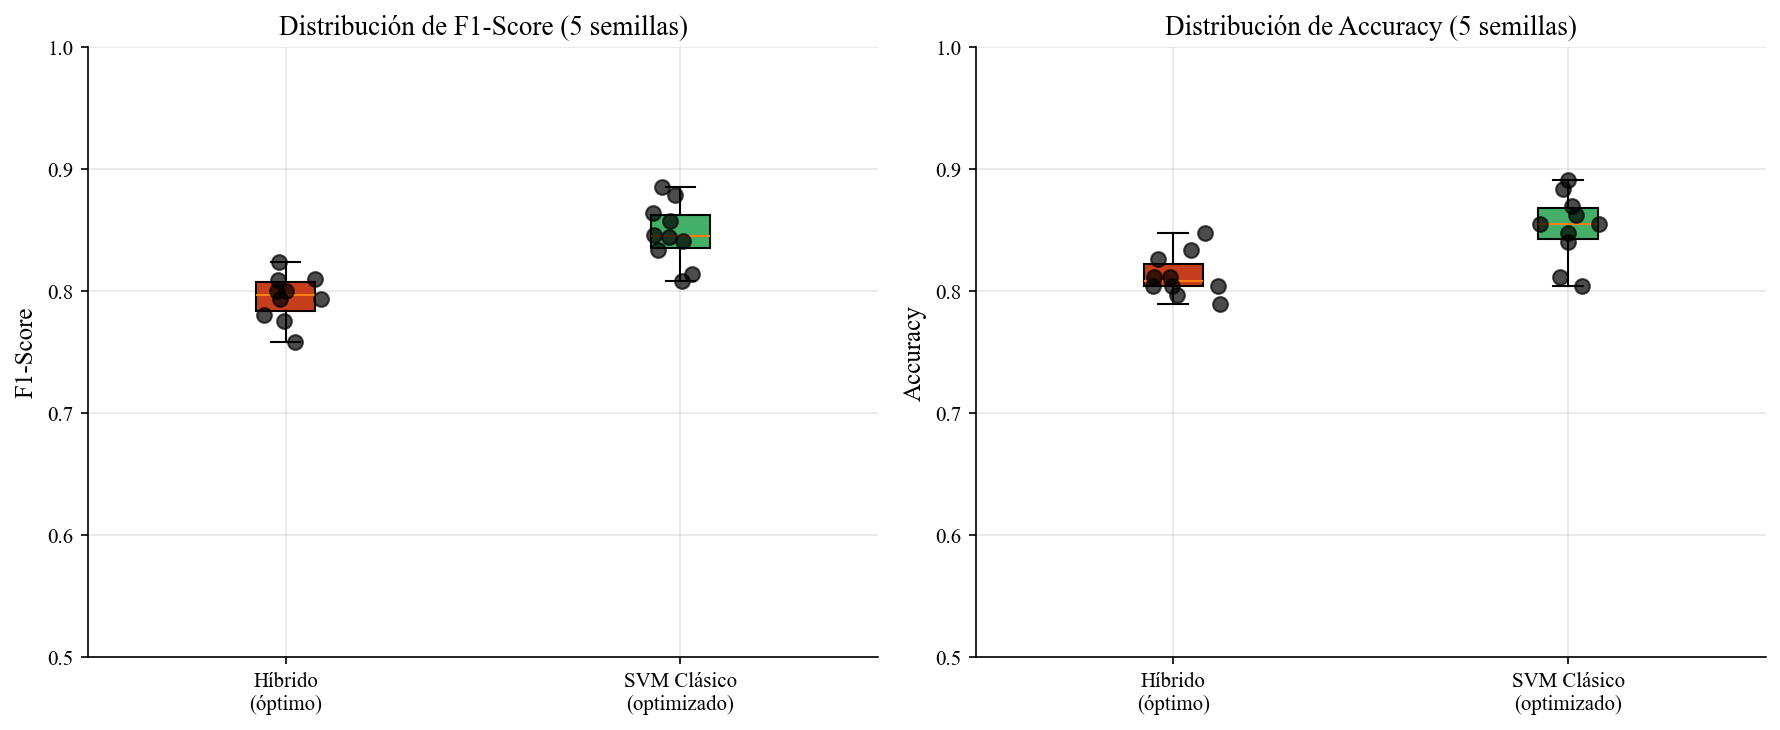


CONCLUSIÓN DE ROBUSTEZ

Diferencia media F1 (Híbrido - SVM): -0.0528
→ El SVM Clásico es consistentemente mejor (5.28% mejor en F1)


In [43]:
# =============================================================================
# RESUMEN Y VISUALIZACIÓN DE ROBUSTEZ ESTADÍSTICA
# =============================================================================

# Calcular estadísticas
print("="*70)
print("RESUMEN DE ROBUSTEZ ESTADÍSTICA")
print("="*70)

for model_name, metrics in robustness_results.items():
    f1_mean = np.mean(metrics['f1'])
    f1_std = np.std(metrics['f1'])
    acc_mean = np.mean(metrics['accuracy'])
    acc_std = np.std(metrics['accuracy'])
    
    print(f"\n{model_name}:")
    print(f"  F1-Score:  {f1_mean:.4f} ± {f1_std:.4f}")
    print(f"  Accuracy:  {acc_mean:.4f} ± {acc_std:.4f}")

# Visualización: Box plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Box plot F1-Score
data_f1 = [robustness_results['Híbrido']['f1'], robustness_results['SVM Clásico']['f1']]
bp1 = axes[0].boxplot(data_f1, labels=['Híbrido\n(óptimo)', 'SVM Clásico\n(optimizado)'], 
                       patch_artist=True)
bp1['boxes'][0].set_facecolor(COLORS['hybrid_1'])
bp1['boxes'][1].set_facecolor(COLORS['classical'])
axes[0].set_ylabel('F1-Score')
axes[0].set_title('Distribución de F1-Score (5 semillas)')
axes[0].set_ylim(0.5, 1.0)

# Añadir puntos individuales
for i, (model, data) in enumerate(zip(['Híbrido', 'SVM Clásico'], data_f1)):
    x = np.random.normal(i+1, 0.04, size=len(data))
    axes[0].scatter(x, data, alpha=0.7, color='black', s=50, zorder=5)

# Box plot Accuracy
data_acc = [robustness_results['Híbrido']['accuracy'], robustness_results['SVM Clásico']['accuracy']]
bp2 = axes[1].boxplot(data_acc, labels=['Híbrido\n(óptimo)', 'SVM Clásico\n(optimizado)'], 
                       patch_artist=True)
bp2['boxes'][0].set_facecolor(COLORS['hybrid_1'])
bp2['boxes'][1].set_facecolor(COLORS['classical'])
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Distribución de Accuracy (5 semillas)')
axes[1].set_ylim(0.5, 1.0)

# Añadir puntos individuales
for i, (model, data) in enumerate(zip(['Híbrido', 'SVM Clásico'], data_acc)):
    x = np.random.normal(i+1, 0.04, size=len(data))
    axes[1].scatter(x, data, alpha=0.7, color='black', s=50, zorder=5)

plt.tight_layout()
plt.savefig('robustness_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

# Test estadístico simple (diferencia de medias)
f1_diff = np.mean(robustness_results['Híbrido']['f1']) - np.mean(robustness_results['SVM Clásico']['f1'])
print("\n" + "="*70)
print("CONCLUSIÓN DE ROBUSTEZ")
print("="*70)
print(f"\nDiferencia media F1 (Híbrido - SVM): {f1_diff:+.4f}")

if f1_diff > 0:
    print(f"→ El modelo Híbrido es consistentemente mejor (+{100*f1_diff:.2f}% en F1)")
else:
    print(f"→ El SVM Clásico es consistentemente mejor ({100*abs(f1_diff):.2f}% mejor en F1)")


### 3.5 Análisis Crítico y Conclusiones


In [41]:
# =============================================================================
# RESUMEN DE HALLAZGOS
# =============================================================================

# Encontrar el mejor modelo cuántico
quantum_models = {k: v for k, v in results.items() if 'Clásico' not in k}
best_quantum = max(quantum_models.items(), key=lambda x: x[1]['f1'])

# Comparación con baseline
classical_f1 = results['SVM Clásico (RBF)']['f1']
best_quantum_f1 = best_quantum[1]['f1']
improvement = ((best_quantum_f1 - classical_f1) / classical_f1) * 100

print("="*70)
print("RESUMEN DE HALLAZGOS")
print("="*70)
print(f"\n1. MEJOR MODELO CUÁNTICO/HÍBRIDO: {best_quantum[0]}")
print(f"   - F1-Score: {best_quantum_f1:.4f}")
print(f"   - Accuracy: {best_quantum[1]['accuracy']:.4f}")

print(f"\n2. BASELINE CLÁSICO (SVM RBF):")
print(f"   - F1-Score: {classical_f1:.4f}")
print(f"   - Accuracy: {results['SVM Clásico (RBF)']['accuracy']:.4f}")

print(f"\n3. COMPARACIÓN:")
if improvement > 0:
    print(f"   - El mejor modelo cuántico supera al baseline en {improvement:.1f}% (F1-Score)")
else:
    print(f"   - El baseline clásico supera al mejor modelo cuántico en {-improvement:.1f}% (F1-Score)")

print(f"\n4. EFICIENCIA COMPUTACIONAL:")
print(f"   - Tiempo más rápido: SVM Clásico ({results['SVM Clásico (RBF)']['time']:.3f}s)")
print(f"   - Tiempo QSVM: {results['QSVM']['time']:.1f}s (kernel cuántico es costoso)")

print("\n" + "="*70)


RESUMEN DE HALLAZGOS

1. MEJOR MODELO CUÁNTICO/HÍBRIDO: NN Clásica (Ablation)
   - F1-Score: 0.8226
   - Accuracy: 0.8406

2. BASELINE CLÁSICO (SVM RBF):
   - F1-Score: 0.8085
   - Accuracy: 0.8043

3. COMPARACIÓN:
   - El mejor modelo cuántico supera al baseline en 1.7% (F1-Score)

4. EFICIENCIA COMPUTACIONAL:
   - Tiempo más rápido: SVM Clásico (4.704s)
   - Tiempo QSVM: 462.6s (kernel cuántico es costoso)



### Conclusiones Finales

#### Rendimiento de los Modelos

Los experimentos realizados permiten extraer las siguientes conclusiones:

1. **QSVM (Kernel Cuántico):** El kernel cuántico proporciona una alternativa al kernel clásico RBF. Sin embargo, su coste computacional es significativamente mayor debido a la necesidad de evaluar el circuito cuántico O(n²) veces para construir la matriz de Gram.

2. **QNN (Red Neuronal Cuántica):** El modelo puramente cuántico muestra una capacidad de aprendizaje limitada con pocas capas variacionales. Aumentar el número de capas mejora la expresividad pero incrementa el riesgo de *barren plateaus* y el tiempo de entrenamiento.

3. **Red Híbrida:** La combinación de capas clásicas y cuánticas ofrece un buen balance. Las capas clásicas pueden preprocesar los datos y la capa cuántica aporta transformaciones no lineales en el espacio de Hilbert.

#### Coste Computacional vs Beneficio

En la era NISQ (Noisy Intermediate-Scale Quantum), los modelos cuánticos enfrentan limitaciones:
- **Simulación costosa:** Sin hardware cuántico real, la simulación clásica es exponencialmente costosa.
- **Ruido:** Los dispositivos reales introducen errores que degradan el rendimiento.
- **Escalabilidad:** Aumentar qubits mejora la expresividad pero dificulta el entrenamiento.

#### Recomendaciones

- Para **aplicaciones prácticas actuales**, los modelos clásicos siguen siendo preferibles por su eficiencia.
- Los modelos **híbridos** son prometedores para explorar ventajas cuánticas con recursos limitados.
- El **QSVM** puede ser útil cuando se busca un kernel altamente no lineal, asumiendo el coste computacional.

#### Trabajo Futuro

1. Ejecutar en hardware cuántico real para evaluar el impacto del ruido.
2. Explorar técnicas de mitigación de errores.
3. Investigar *quantum advantage* en datasets de mayor dimensionalidad.
4. Comparar con más arquitecturas de ansätze variacionales.


---

## Referencias

1. Schuld, M., & Petruccione, F. (2021). *Machine Learning with Quantum Computers*. Springer.
2. Havlíček, V., et al. (2019). Supervised learning with quantum-enhanced feature spaces. *Nature*, 567(7747), 209-212.
3. Cerezo, M., et al. (2021). Variational quantum algorithms. *Nature Reviews Physics*, 3(9), 625-644.
4. PennyLane Documentation: https://pennylane.ai/qml/
5. UCI Machine Learning Repository - Statlog (Australian Credit Approval): https://archive.ics.uci.edu/ml/datasets/statlog+(australian+credit+approval)

---

